<a href="https://colab.research.google.com/github/duhanlhycel-64/lhycel-duhan-portfolio/blob/ml-projects/DPWH_Flood_Control_Data_Mining_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Study Title**

##Data Mining and Exploratory Analysis of Flood Control Infrastructure Projects in the Philippines

## Introduction

I am Ma. Lhycel R. Duhan, a fourth-year Bachelor of Science in Computer Engineering student. As a student, I became interested in exploring data mining on my own and applying the concepts and techniques that I have learned throughout my studies.

For this study, I chose a dataset containing DPWH flood control infrastructure projects in the Philippines. My main purpose is to explore the dataset and understand what meaningful patterns can be discovered from it. I wanted to apply the lessons I have learned in school to a real-world dataset and see how data-mining techniques can be used beyond classroom examples.

I first used Exploratory Data Analysis (EDA) to understand the dataset and examine the distribution of the projects based on factors such as funding year, location, type of work, financial values, project duration, and contractor participation. I then applied K-Means clustering to explore whether projects could be grouped based on similar characteristics. Isolation Forest was also used to identify projects with unusual combinations of financial values and project duration.

Overall, this study serves as an independent exploration of a real-world dataset using concepts learned in school. Rather than attempting to directly solve the flooding problem in the Philippines, the study focuses on discovering patterns, similarities, and potential outliers within the available flood control project data. Through this process, I aim to better understand how data-mining techniques can be applied to real-world engineering and infrastructure data.

In [ ]:
import os

print(os.listdir('/content'))

['.config', 'sample_data']


In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

Saving dpwh_flood_control_projects.csv to dpwh_flood_control_projects.csv
Rows and columns: (9855, 22)

Column names:
['MainIsland', 'Region', 'Province', 'LegislativeDistrict', 'Municipality', 'DistrictEngineeringOffice', 'ProjectId', 'ProjectName', 'TypeOfWork', 'FundingYear', 'ContractId', 'ApprovedBudgetForContract', 'ContractCost', 'ActualCompletionDate', 'Contractor', 'ContractorCount', 'StartDate', 'ProjectLatitude', 'ProjectLongitude', 'ProvincialCapital', 'ProvincialCapitalLatitude', 'ProvincialCapitalLongitude']

First 5 rows:


,MainIsland,Region,Province,LegislativeDistrict,Municipality,DistrictEngineeringOffice,ProjectId,ProjectName,TypeOfWork,FundingYear,...,ContractCost,ActualCompletionDate,Contractor,ContractorCount,StartDate,ProjectLatitude,ProjectLongitude,ProvincialCapital,ProvincialCapitalLatitude,ProvincialCapitalLongitude
0,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),NaN,Apayao 2nd District Engineering Office,P00526268LZ,Construction of Poblacion Flood Control Struct...,Construction of Flood Mitigation Structure,2021,...,92692943.8,2022-10-03,ASC CONSTRUCTION & CONCRETE PRODUCTS,1,2021-03-18,18.25091,121.047570,Kabugao,18.0215,121.1716
1,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),NaN,Apayao 2nd District Engineering Office,P00526368LZ,Construction of Cabicungan Flood Control Struc...,Construction of Flood Mitigation Structure,2021,...,47521251.3,2022-11-24,ASC CONSTRUCTION & CONCRETE PRODUCTS,1,2021-12-01,18.51180,121.078290,Kabugao,18.0215,121.1716
2,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),NaN,Apayao 2nd District Engineering Office,P00526369LZ,Construction of Sipa-San Mariano Flood Control...,Construction of Flood Mitigation Structure,2021,...,45942583.67,2022-11-28,ASC CONSTRUCTION & CONCRETE PRODUCTS,1,2021-12-01,18.27023,121.420220,Kabugao,18.0215,121.1716
3,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),NaN,Apayao 2nd District Engineering Office,P00561270LZ,Construction of Sta. Filomena Floodway/ Flood ...,Construction of Flood Mitigation Structure,2021,...,9900000,2022-12-15,ASC CONSTRUCTION & CONCRETE PRODUCTS,1,2021-12-01,18.53566,121.080200,Kabugao,18.0215,121.1716
4,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),NaN,Apayao 2nd District Engineering Office,P00561652LZ,"Construction of Sinigpit Flood Control, Calana...",Construction of Flood Mitigation Structure,2021,...,4950000,2022-09-23,ALEPHNORTH PEAK CONSTRUCTION AND DEVELOPMENT CO.,1,2021-12-01,18.52723,121.096812,Kabugao,18.0215,121.1716



Data types:


,0
MainIsland,object
Region,object
Province,object
LegislativeDistrict,object
Municipality,object
DistrictEngineeringOffice,object
ProjectId,object
ProjectName,object
TypeOfWork,object
FundingYear,int64



Missing values:


,0
MainIsland,0
Region,0
Province,0
LegislativeDistrict,0
Municipality,666
DistrictEngineeringOffice,0
ProjectId,0
ProjectName,0
TypeOfWork,0
FundingYear,0


##DATASET INSPECTION

In [ ]:
# inspect unique values and basic information

print("Dataset shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFunding years:")
print(sorted(df["FundingYear"].unique()))

print("\nNumber of unique values:")
display(df.nunique().sort_values(ascending=False))

print("\nType of Work:")
display(df["TypeOfWork"].value_counts())

print("\nMain Island:")
display(df["MainIsland"].value_counts())

print("\nTop 15 Regions:")
display(df["Region"].value_counts().head(15))

print("\nTop 15 Provinces:")
display(df["Province"].value_counts().head(15))

Dataset shape: (9855, 22)

Duplicate rows: 0

Funding years:
[np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Number of unique values:


,0
ProjectId,9827
ProjectName,9712
ContractId,9698
ProjectLatitude,9500
ProjectLongitude,9471
ContractCost,8025
ApprovedBudgetForContract,4916
Contractor,2409
Municipality,1197
ActualCompletionDate,1028



Type of Work:


,count
TypeOfWork,
Construction of Flood Mitigation Structure,6352
Construction of Revetment,747
Construction of Slope Protection Structure,739
Construction of Drainage Structure,679
Rehabilitation / Major Repair of Flood Control Structure,648
Construction of Dike,225
Rehabilitation / Major Repair of Drainage Structure,215
Construction of Flood Mitigation Facility,170
Rehabilitation / Major Repair of Slope Protection Structure,41



Main Island:


,count
MainIsland,
Luzon,6698
Visayas,1637
Mindanao,1520



Top 15 Regions:


,count
Region,
Region III,1617
National Capital Region,1058
Region V,866
Region I,851
Region IV-A,829
Region II,628
Region VII,614
Region VIII,517
Region VI,505



Top 15 Provinces:


,count
Province,
Metro Manila,1058
Bulacan,668
Cebu,414
Isabela,337
Pangasinan,313
Pampanga,293
Albay,273
Leyte,262
Tarlac,258


##FINANCIAL DATA INSPECTION

In [ ]:
print("Approved Budget samples:")
display(
    df["ApprovedBudgetForContract"]
    .drop_duplicates()
    .head(20)
)

print("\nContract Cost samples:")
display(
    df["ContractCost"]
    .drop_duplicates()
    .head(20)
)

Approved Budget samples:


,ApprovedBudgetForContract
0,96500000
1,49000000
2,47423180
3,9900000
4,4950000
5,39199819.73
6,82914680
7,23519997.48
8,15678924.68
9,51761907.66



Contract Cost samples:


,ContractCost
0,92692943.8
1,47521251.3
2,45942583.67
3,9900000
4,4950000
5,38292917.46
6,80309010.27
7,22928490.31
8,15680000
9,51762600


In [ ]:
print("Approved Budget data types:", df["ApprovedBudgetForContract"].dtype)
print("Contract Cost data type:", df["ContractCost"].dtype)

print("\nRows with non-numeric budget values:")
display(
    df[
        ~df["ApprovedBudgetForContract"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace(".", "", regex=False)
        .str.isnumeric()
    ][["ApprovedBudgetForContract"]].head(20)
)

Approved Budget data types: object
Contract Cost data type: object

Rows with non-numeric budget values:


,ApprovedBudgetForContract
81,Clustered with Contract ID 23PD0057
84,Clustered with Contract ID 24PD0027
334,Clustered with Contract ID 22PJ0044
335,Clustered with Contract ID 22PJ0044
342,Clustered with Contract ID 22P00087
363,MYCA with Project ID P00421301LZ
1998,Clustered with Contract ID 24AJ0096
2124,Clustered with Contract ID 24AJ0096
2125,Clustered with Contract ID 24AJ0097
2198,Clustered with Contract ID 23AJ0125


In [ ]:
# Create numeric versions of the financial columns
# Invalid text values will become NaN

df["ApprovedBudget_numeric"] = pd.to_numeric(
    df["ApprovedBudgetForContract"],
    errors="coerce"
)

df["ContractCost_numeric"] = pd.to_numeric(
    df["ContractCost"],
    errors="coerce"
)

print("Missing values after numeric conversion:")

print(
    "Approved Budget:",
    df["ApprovedBudget_numeric"].isna().sum()
)

print(
    "Contract Cost:",
    df["ContractCost_numeric"].isna().sum()
)

Missing values after numeric conversion:
Approved Budget: 157
Contract Cost: 28


In [ ]:
print("Non-numeric Approved Budget records:")

display(
    df[
        df["ApprovedBudget_numeric"].isna()
    ][
        [
            "ProjectId",
            "ProjectName",
            "ContractId",
            "ApprovedBudgetForContract",
            "ContractCost"
        ]
    ]
)

Non-numeric Approved Budget records:


,ProjectId,ProjectName,ContractId,ApprovedBudgetForContract,ContractCost
81,P00726656LZ,Construction of Flood Mitigation Facilities/Dr...,23PD0057,Clustered with Contract ID 23PD0057,49000000
84,P00821529LZ,Construction of Flood Mitigation Structure alo...,24PD0027,Clustered with Contract ID 24PD0027,49000000
334,P00620481LZ,Construction of Mapacopaco Flood Control Struc...,22PJ0044,Clustered with Contract ID 22PJ0044,31817660
335,P00620482LZ,Construction of Mapacopaco Flood Control Struc...,22PJ0044,Clustered with Contract ID 22PJ0044,20914465.8
342,P00621003LZ,Construction of Boliwong Flood Control Structu...,22P00087,Clustered with Contract ID 22P00087,36551362.81
...,...,...,...,...,...
9463,P00732169MN,Construction of River Bank Protection along Ma...,23MG0001,Clustered with Contract ID 23MG0001,24442424.42
9467,P00734378MN,Construction of River Bank Protection along Ma...,23M00231,Clustered with Contract ID 23M00231,77101733.66
9470,P00734377MN,Construction of River Bank Protection along Ba...,23M00231,Clustered with Contract ID 23M00231,75619408.99
9477,P00732168MN,Construction of River Bank Protection along Ba...,23MG0034,Clustered with Contract ID 23MG0034,24495251.86


In [ ]:
print("Non-numeric Contract Cost records:")

display(
    df[
        df["ContractCost_numeric"].isna()
    ][
        [
            "ProjectId",
            "ProjectName",
            "ContractId",
            "ApprovedBudgetForContract",
            "ContractCost"
        ]
    ]
)

Non-numeric Contract Cost records:


,ProjectId,ProjectName,ContractId,ApprovedBudgetForContract,ContractCost
363,P00421301LZ,Construction of Revetment Wall/Sheetpiling of ...,20OC0135,MYCA with Project ID P00421301LZ,MYCA with Project ID P00421301LZ
2293,P00448928LZ,Construction of Flood Mitigation Structure alo...,20BB0083,MYCA with Project ID P00448930LZ,MYCA with Project ID P00448930LZ
2295,P00448930LZ,Construction of Flood Mitigation Structure alo...,20BB0085,MYCA with Project ID P00448930LZ,MYCA with Project ID P00448930LZ
4658,P00421352LZ,Construction of Detention Pond at Brgy. Mampla...,20D00058,MYCA with Project ID P00421352LZ,MYCA with Project ID P00421352LZ
5843,P00443081MN,Construction/rehabilitation of slope protectio...,20JB0060,MYCA with Project ID P00443081MN,MYCA with Project ID P00443081MN
5966,P00448880LZ,"Rehabilation of Flood Control, Baao Lake Outfa...",20FN0097,MYCA with Project ID P00448880LZ,MYCA with Project ID P00448880LZ
6216,P00448861LZ,"Construction of Flood Control Structure, Bulan...",20F00105,MYCA with Project ID P00448861LZ,MYCA with Project ID P00448861LZ
6218,P00448887LZ,Rehabilitation/Reconstruction of Flood Control...,20F00106,MYCA with Project ID P00448861LZ,MYCA with Project ID P00448861LZ
6833,P00442501VS,Construction of Slope Protection and Improveme...,20G00090,MYCA with Project ID P00442501VS,MYCA with Project ID P00442501VS
7000,P00420350VS,Construction of Revetment at Sibalom Bridge (A...,20G00098,MYCA with Project ID P00420350VS,MYCA with Project ID P00420350VS


In [ ]:
# Convert financial columns to numeric values
# Non-numeric entries such as clustered/MYCA records become NaN

df["ApprovedBudget_numeric"] = pd.to_numeric(
    df["ApprovedBudgetForContract"],
    errors="coerce"
)

df["ContractCost_numeric"] = pd.to_numeric(
    df["ContractCost"],
    errors="coerce"
)

print("Financial data cleaning summary")
print("-" * 40)

print(
    "Total projects:",
    len(df)
)

print(
    "Available approved budgets:",
    df["ApprovedBudget_numeric"].notna().sum()
)

print(
    "Missing approved budgets:",
    df["ApprovedBudget_numeric"].isna().sum()
)

print(
    "Available contract costs:",
    df["ContractCost_numeric"].notna().sum()
)

print(
    "Missing contract costs:",
    df["ContractCost_numeric"].isna().sum()
)

Financial data cleaning summary
----------------------------------------
Total projects: 9855
Available approved budgets: 9698
Missing approved budgets: 157
Available contract costs: 9827
Missing contract costs: 28


In [ ]:
print("Start Date samples:")
display(df["StartDate"].head(10))

print("\nActual Completion Date samples:")
display(df["ActualCompletionDate"].head(10))

print("\nUnique Start Date formats:")
display(df["StartDate"].drop_duplicates().head(20))

Start Date samples:


,StartDate
0,2021-03-18
1,2021-12-01
2,2021-12-01
3,2021-12-01
4,2021-12-01
5,2021-12-02
6,2021-12-22
7,2022-02-09
8,2022-03-01
9,2022-04-04



Actual Completion Date samples:


,ActualCompletionDate
0,2022-10-03
1,2022-11-24
2,2022-11-28
3,2022-12-15
4,2022-09-23
5,2022-09-24
6,2023-04-14
7,2022-11-02
8,2022-12-22
9,2023-05-30



Unique Start Date formats:


,StartDate
0,2021-03-18
1,2021-12-01
5,2021-12-02
6,2021-12-22
7,2022-02-09
8,2022-03-01
9,2022-04-04
10,2023-02-12
12,2023-04-12
14,2022-03-25


In [ ]:
# Convert date columns to datetime
df["StartDate"] = pd.to_datetime(
    df["StartDate"],
    errors="coerce"
)

df["ActualCompletionDate"] = pd.to_datetime(
    df["ActualCompletionDate"],
    errors="coerce"
)

print("StartDate dtype:", df["StartDate"].dtype)
print("ActualCompletionDate dtype:", df["ActualCompletionDate"].dtype)

print("\nMissing StartDate:", df["StartDate"].isna().sum())
print("Missing ActualCompletionDate:", df["ActualCompletionDate"].isna().sum())

StartDate dtype: datetime64[ns]
ActualCompletionDate dtype: datetime64[ns]

Missing StartDate: 0
Missing ActualCompletionDate: 0


### Calculate Project Duration

In [ ]:
# Calculate project duration in days
df["ProjectDurationDays"] = (
    df["ActualCompletionDate"] - df["StartDate"]
).dt.days

print("Project duration summary:")
display(df["ProjectDurationDays"].describe())

Project duration summary:


,ProjectDurationDays
count,9855.000000
mean,248.097210
std,137.559406
min,14.000000
25%,161.000000
50%,228.000000
75%,299.000000
max,2012.000000


### Check for Invalid Project Durations

In [ ]:
print("Projects with negative duration:")
display(
    df[df["ProjectDurationDays"] < 0][
        [
            "ProjectId",
            "StartDate",
            "ActualCompletionDate",
            "ProjectDurationDays"
        ]
    ]
)

Projects with negative duration:


,ProjectId,StartDate,ActualCompletionDate,ProjectDurationDays


### Check Missing and Zero Project Durations

In [ ]:
print("Missing project duration:",
      df["ProjectDurationDays"].isna().sum())

print("Zero-day projects:",
      (df["ProjectDurationDays"] == 0).sum())

Missing project duration: 0
Zero-day projects: 0


### Check Missing Project Coordinates

In [ ]:
# Check missing project coordinates

print(
    "Missing ProjectLatitude:",
    df["ProjectLatitude"].isna().sum()
)

print(
    "Missing ProjectLongitude:",
    df["ProjectLongitude"].isna().sum()
)

print(
    "Missing ProvincialCapitalLatitude:",
    df["ProvincialCapitalLatitude"].isna().sum()
)

print(
    "Missing ProvincialCapitalLongitude:",
    df["ProvincialCapitalLongitude"].isna().sum()
)

Missing ProjectLatitude: 0
Missing ProjectLongitude: 0
Missing ProvincialCapitalLatitude: 0
Missing ProvincialCapitalLongitude: 0


### Check Coordinate Ranges

In [ ]:
# Display descriptive statistics for geographic coordinates

display(
    df[
        [
            "ProjectLatitude",
            "ProjectLongitude",
            "ProvincialCapitalLatitude",
            "ProvincialCapitalLongitude"
        ]
    ].describe()
)

,ProjectLatitude,ProjectLongitude,ProvincialCapitalLatitude,ProvincialCapitalLongitude
count,9855.000000,9855.000000,9855.000000,9855.000000
mean,13.197804,122.254094,13.216237,122.257637
std,3.146945,1.768041,3.124439,1.779151
min,5.767601,117.061736,6.052200,118.735300
25%,10.718490,120.910978,10.676300,120.810600
50%,14.273611,121.435556,14.279200,121.441700
75%,15.157180,123.722497,15.034500,123.853900
max,20.455773,126.569467,20.448700,126.216600


### Inspect Missing Municipality Records

In [ ]:
# Inspect records with missing municipality

missing_municipality = df[df["Municipality"].isna()]

print(
    "Records with missing Municipality:",
    len(missing_municipality)
)

display(
    missing_municipality[
        [
            "Region",
            "Province",
            "LegislativeDistrict",
            "DistrictEngineeringOffice",
            "ProjectName",
            "ProjectLatitude",
            "ProjectLongitude"
        ]
    ].head(20)
)

Records with missing Municipality: 666


,Region,Province,LegislativeDistrict,DistrictEngineeringOffice,ProjectName,ProjectLatitude,ProjectLongitude
0,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,Construction of Poblacion Flood Control Struct...,18.250910,121.047570
1,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,Construction of Cabicungan Flood Control Struc...,18.511800,121.078290
2,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,Construction of Sipa-San Mariano Flood Control...,18.270230,121.420220
3,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,Construction of Sta. Filomena Floodway/ Flood ...,18.535660,121.080200
4,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,"Construction of Sinigpit Flood Control, Calana...",18.527230,121.096812
5,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 1st District Engineering Office,Construction of Nabuangan River (Upstream) Flo...,17.800000,121.315833
6,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 1st District Engineering Office,Construction of Nabuangan (Upstream) Flood Con...,17.800278,121.308889
34,Cordillera Administrative Region,Benguet,BENGUET (LEGISLATIVE DISTRICT),Benguet 1st District Engineering Office,Construction of Flood Mitigation Structure wit...,16.464227,120.587735
35,Cordillera Administrative Region,Benguet,BENGUET (LEGISLATIVE DISTRICT),Benguet 2nd District Engineering Office,"Construction of Ampusongan Flood Control, Baku...",16.782860,120.729420
36,Cordillera Administrative Region,Benguet,BENGUET (LEGISLATIVE DISTRICT),Benguet 2nd District Engineering Office,Construction of Baguyos Flood Control at Baran...,16.918130,120.765840


### Inspect Missing Municipality Records

In [ ]:
# Inspect records with missing municipality values

missing_municipality = df[df["Municipality"].isna()]

print(
    "Records with missing Municipality:",
    len(missing_municipality)
)

display(
    missing_municipality[
        [
            "Region",
            "Province",
            "LegislativeDistrict",
            "DistrictEngineeringOffice",
            "ProjectName",
            "ProjectLatitude",
            "ProjectLongitude"
        ]
    ].head(20)
)

Records with missing Municipality: 666


,Region,Province,LegislativeDistrict,DistrictEngineeringOffice,ProjectName,ProjectLatitude,ProjectLongitude
0,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,Construction of Poblacion Flood Control Struct...,18.250910,121.047570
1,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,Construction of Cabicungan Flood Control Struc...,18.511800,121.078290
2,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,Construction of Sipa-San Mariano Flood Control...,18.270230,121.420220
3,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,Construction of Sta. Filomena Floodway/ Flood ...,18.535660,121.080200
4,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,"Construction of Sinigpit Flood Control, Calana...",18.527230,121.096812
5,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 1st District Engineering Office,Construction of Nabuangan River (Upstream) Flo...,17.800000,121.315833
6,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 1st District Engineering Office,Construction of Nabuangan (Upstream) Flood Con...,17.800278,121.308889
34,Cordillera Administrative Region,Benguet,BENGUET (LEGISLATIVE DISTRICT),Benguet 1st District Engineering Office,Construction of Flood Mitigation Structure wit...,16.464227,120.587735
35,Cordillera Administrative Region,Benguet,BENGUET (LEGISLATIVE DISTRICT),Benguet 2nd District Engineering Office,"Construction of Ampusongan Flood Control, Baku...",16.782860,120.729420
36,Cordillera Administrative Region,Benguet,BENGUET (LEGISLATIVE DISTRICT),Benguet 2nd District Engineering Office,Construction of Baguyos Flood Control at Baran...,16.918130,120.765840


### Missing Municipality Records by Province

In [ ]:
# Count missing municipality records by province

missing_municipality_by_province = (
    missing_municipality["Province"]
    .value_counts()
)

display(missing_municipality_by_province)

,count
Province,
Metro Manila,82
Davao City,60
Rizal,33
Albay,24
Isabela,24
...,...
Marinduque,1
Biliran,1
Bohol,1


##Check Location Information in Project Names

In [ ]:
# Check whether missing Municipality records contain location information in ProjectName

display(
    missing_municipality[
        [
            "Province",
            "DistrictEngineeringOffice",
            "ProjectName",
            "ProjectLatitude",
            "ProjectLongitude"
        ]
    ].head(30)
)

,Province,DistrictEngineeringOffice,ProjectName,ProjectLatitude,ProjectLongitude
0,Apayao,Apayao 2nd District Engineering Office,Construction of Poblacion Flood Control Struct...,18.250910,121.047570
1,Apayao,Apayao 2nd District Engineering Office,Construction of Cabicungan Flood Control Struc...,18.511800,121.078290
2,Apayao,Apayao 2nd District Engineering Office,Construction of Sipa-San Mariano Flood Control...,18.270230,121.420220
3,Apayao,Apayao 2nd District Engineering Office,Construction of Sta. Filomena Floodway/ Flood ...,18.535660,121.080200
4,Apayao,Apayao 2nd District Engineering Office,"Construction of Sinigpit Flood Control, Calana...",18.527230,121.096812
5,Apayao,Apayao 1st District Engineering Office,Construction of Nabuangan River (Upstream) Flo...,17.800000,121.315833
6,Apayao,Apayao 1st District Engineering Office,Construction of Nabuangan (Upstream) Flood Con...,17.800278,121.308889
34,Benguet,Benguet 1st District Engineering Office,Construction of Flood Mitigation Structure wit...,16.464227,120.587735
35,Benguet,Benguet 2nd District Engineering Office,"Construction of Ampusongan Flood Control, Baku...",16.782860,120.729420
36,Benguet,Benguet 2nd District Engineering Office,Construction of Baguyos Flood Control at Baran...,16.918130,120.765840


##Check Missing Municipality by Region

In [ ]:
# Count missing Municipality records by Region

missing_municipality_by_region = (
    missing_municipality["Region"]
    .value_counts()
)

display(missing_municipality_by_region)

,count
Region,
National Capital Region,82
Region XI,71
Cordillera Administrative Region,65
Region IV-A,59
Region V,54
Region II,49
Region IV-B,37
Region VI,36
Region III,35


##Check Missing Municipality by District Engineering Office

In [ ]:
# Count missing Municipality records by District Engineering Office

missing_municipality_by_office = (
    missing_municipality["DistrictEngineeringOffice"]
    .value_counts()
)

display(missing_municipality_by_office.head(30))

,count
DistrictEngineeringOffice,
Davao City District Engineering Office,60
Metro Manila 2nd District Engineering Office,23
Rizal 2nd District Engineering Office,22
Upper Kalinga District Engineering Office,17
Abra District Engineering Office,16
Metro Manila 1st District Engineering Office,15
Albay 1st District Engineering Office,14
Benguet 2nd District Engineering Office,14
Metro Manila 3rd District Engineering Office,13


##DATA CLEANING SUMMARY

In [ ]:
# Summarize the data cleaning and preprocessing results

cleaning_summary = pd.DataFrame({
    "Data Quality Check": [
        "Duplicate records",
        "Missing Municipality",
        "Missing Approved Budget",
        "Missing Contract Cost",
        "Missing Start Date",
        "Missing Actual Completion Date",
        "Missing Project Duration",
        "Zero-day Project Duration",
        "Negative Project Duration",
        "Missing Project Latitude",
        "Missing Project Longitude",
        "Missing Provincial Capital Latitude",
        "Missing Provincial Capital Longitude"
    ],
    "Result": [
        df.duplicated().sum(),
        df["Municipality"].isna().sum(),
        df["ApprovedBudget_numeric"].isna().sum(),
        df["ContractCost_numeric"].isna().sum(),
        df["StartDate"].isna().sum(),
        df["ActualCompletionDate"].isna().sum(),
        df["ProjectDurationDays"].isna().sum(),
        (df["ProjectDurationDays"] == 0).sum(),
        (df["ProjectDurationDays"] < 0).sum(),
        df["ProjectLatitude"].isna().sum(),
        df["ProjectLongitude"].isna().sum(),
        df["ProvincialCapitalLatitude"].isna().sum(),
        df["ProvincialCapitalLongitude"].isna().sum()
    ]
})

display(cleaning_summary)

,Data Quality Check,Result
0,Duplicate records,0
1,Missing Municipality,666
2,Missing Approved Budget,157
3,Missing Contract Cost,28
4,Missing Start Date,0
5,Missing Actual Completion Date,0
6,Missing Project Duration,0
7,Zero-day Project Duration,0
8,Negative Project Duration,0
9,Missing Project Latitude,0


##Final Dataset Information

In [ ]:
# Display the final dataset structure after preprocessing

print("Number of records:", len(df))
print("Number of columns:", len(df.columns))
print("\nData types:")
display(df.dtypes)

Number of records: 9855
Number of columns: 25

Data types:


,0
MainIsland,object
Region,object
Province,object
LegislativeDistrict,object
Municipality,object
DistrictEngineeringOffice,object
ProjectId,object
ProjectName,object
TypeOfWork,object
FundingYear,int64


### EDA 1: Distribution of Projects by Funding Year

In [ ]:
# Count the number of projects for each funding year

projects_by_year = (
    df["FundingYear"]
    .value_counts()
    .sort_index()
)

display(projects_by_year)

,count
FundingYear,
2018,7
2019,3
2020,36
2021,619
2022,3335
2023,3466
2024,2354
2025,35


### EDA 1: Projects by Funding Year Visualization

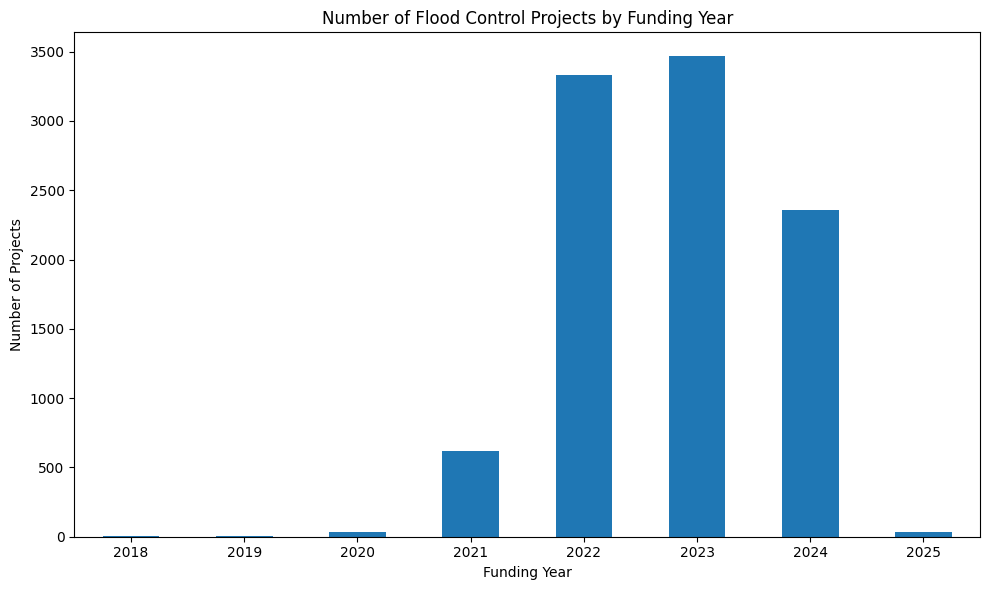

In [ ]:
# Visualize the number of projects by funding year

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

projects_by_year.plot(kind="bar")

plt.title("Number of Flood Control Projects by Funding Year")
plt.xlabel("Funding Year")
plt.ylabel("Number of Projects")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### EDA 1: Percentage Distribution by Funding Year

In [ ]:
# Calculate the percentage distribution of projects by funding year

year_percentage = (
    df["FundingYear"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

display(year_percentage)

,proportion
FundingYear,
2018,0.07
2019,0.03
2020,0.37
2021,6.28
2022,33.84
2023,35.17
2024,23.89
2025,0.36


## INTERPRETATION

The distribution of flood control projects shows a substantial concentration of records between 2022 and 2024. Funding Year 2023 recorded the highest number of projects with 3,466 projects, followed by 2022 with 3,335 and 2024 with 2,354 projects. Earlier years had considerably fewer records, while 2025 also contained relatively few projects. This indicates that the dataset is not evenly distributed across the funding years and that analyses involving temporal patterns should consider the strong concentration of observations in 2022–2024.

##EDA 2 — Projects by Main Island

### EDA 2: Distribution of Projects by Main Island

In [ ]:
# Count the number of projects for each main island

projects_by_island = (
    df["MainIsland"]
    .value_counts()
)

display(projects_by_island)

,count
MainIsland,
Luzon,6698
Visayas,1637
Mindanao,1520


### EDA 2: Projects by Main Island Visualization

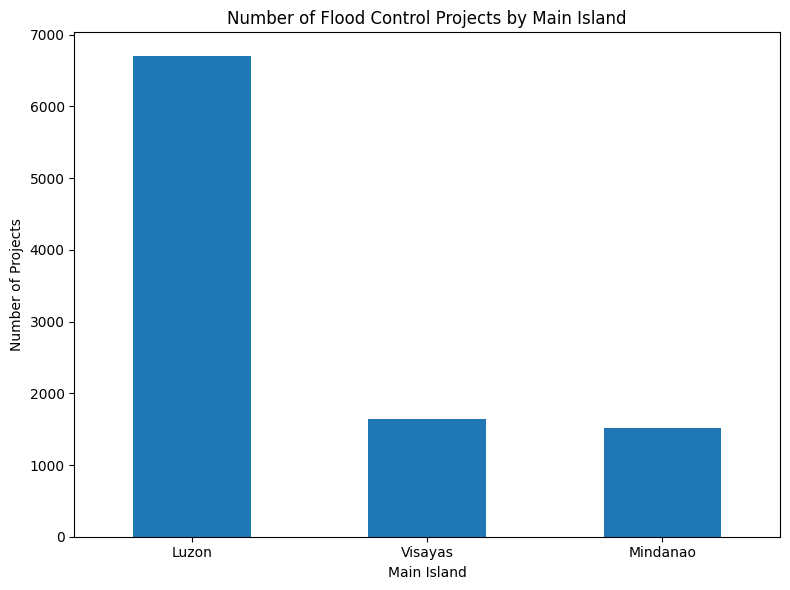

In [ ]:
# Visualize the number of projects by main island

plt.figure(figsize=(8, 6))

projects_by_island.plot(kind="bar")

plt.title("Number of Flood Control Projects by Main Island")
plt.xlabel("Main Island")
plt.ylabel("Number of Projects")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### EDA 2: Percentage Distribution by Main Island

In [ ]:
# Calculate the percentage distribution by main island

island_percentage = (
    df["MainIsland"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(island_percentage)

,proportion
MainIsland,
Luzon,67.97
Visayas,16.61
Mindanao,15.42


##INTERPRETATION

The distribution by main island shows that Luzon accounts for the majority of recorded flood control projects, with 6,698 projects or 67.97% of the dataset. Visayas accounts for 1,637 projects (16.61%), while Mindanao accounts for 1,520 projects (15.42%). This indicates a substantial geographic concentration of the recorded projects in Luzon.

##EDA 3 — Projects by Region

### EDA 3: Distribution of Projects by Region

In [ ]:
# Count the number of projects for each region

projects_by_region = (
    df["Region"]
    .value_counts()
    .sort_values(ascending=False)
)

display(projects_by_region)

,count
Region,
Region III,1617
National Capital Region,1058
Region V,866
Region I,851
Region IV-A,829
Region II,628
Region VII,614
Region VIII,517
Region VI,505


### EDA 3: Projects by Region Visualization

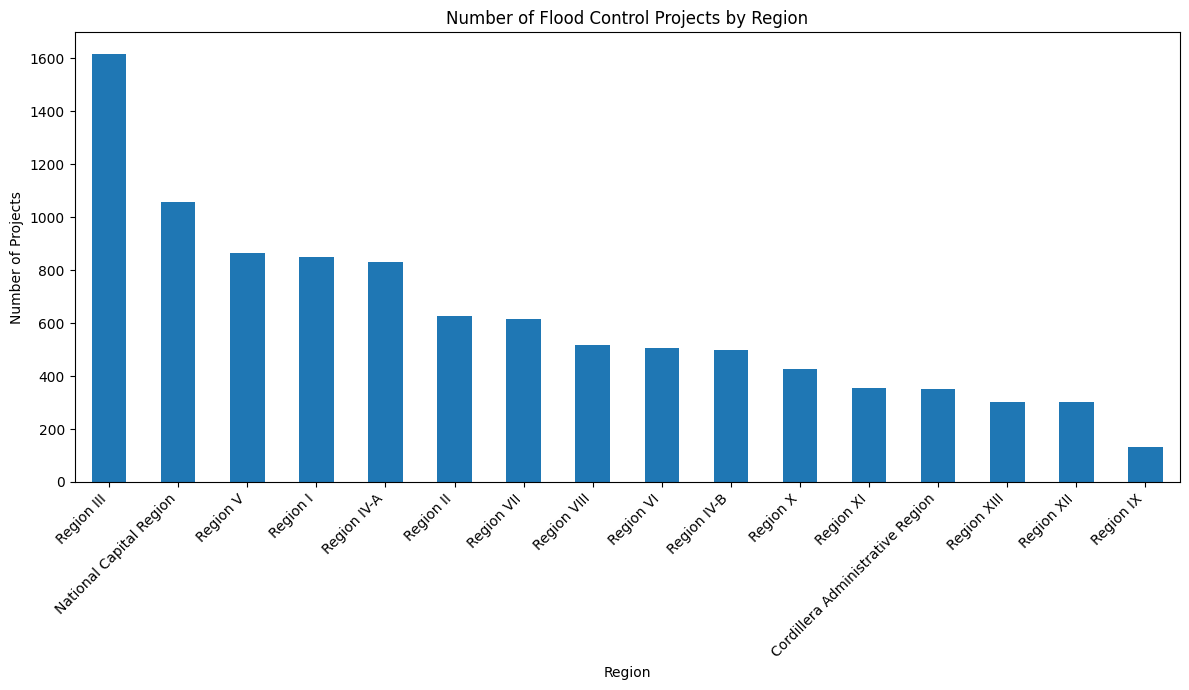

In [ ]:
# Visualize the number of projects by region

plt.figure(figsize=(12, 7))

projects_by_region.plot(kind="bar")

plt.title("Number of Flood Control Projects by Region")
plt.xlabel("Region")
plt.ylabel("Number of Projects")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### EDA 3: Percentage Distribution by Region

In [ ]:
# Calculate the percentage distribution by region

region_percentage = (
    df["Region"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(region_percentage)

,proportion
Region,
Region III,16.41
National Capital Region,10.74
Region V,8.79
Region I,8.64
Region IV-A,8.41
Region II,6.37
Region VII,6.23
Region VIII,5.25
Region VI,5.12


##INTERPRETATION

Region III recorded the highest number of flood control projects in the dataset, with 1,617 projects or 16.41% of the total. This was followed by the National Capital Region with 1,058 projects (10.74%) and Region V with 866 projects (8.79%). In contrast, Region IX recorded the lowest number of projects at 133 (1.35%). The results indicate that the distribution of recorded flood control projects varies considerably across regions.

##EDA 4 — Projects by Province

### EDA 4: Top Provinces by Number of Flood Control Projects

In [ ]:
# Count projects by province and select the top 15

projects_by_province = (
    df["Province"]
    .value_counts()
    .head(15)
)

display(projects_by_province)

,count
Province,
Metro Manila,1058
Bulacan,668
Cebu,414
Isabela,337
Pangasinan,313
Pampanga,293
Albay,273
Leyte,262
Tarlac,258


### EDA 4: Top 15 Provinces Visualization

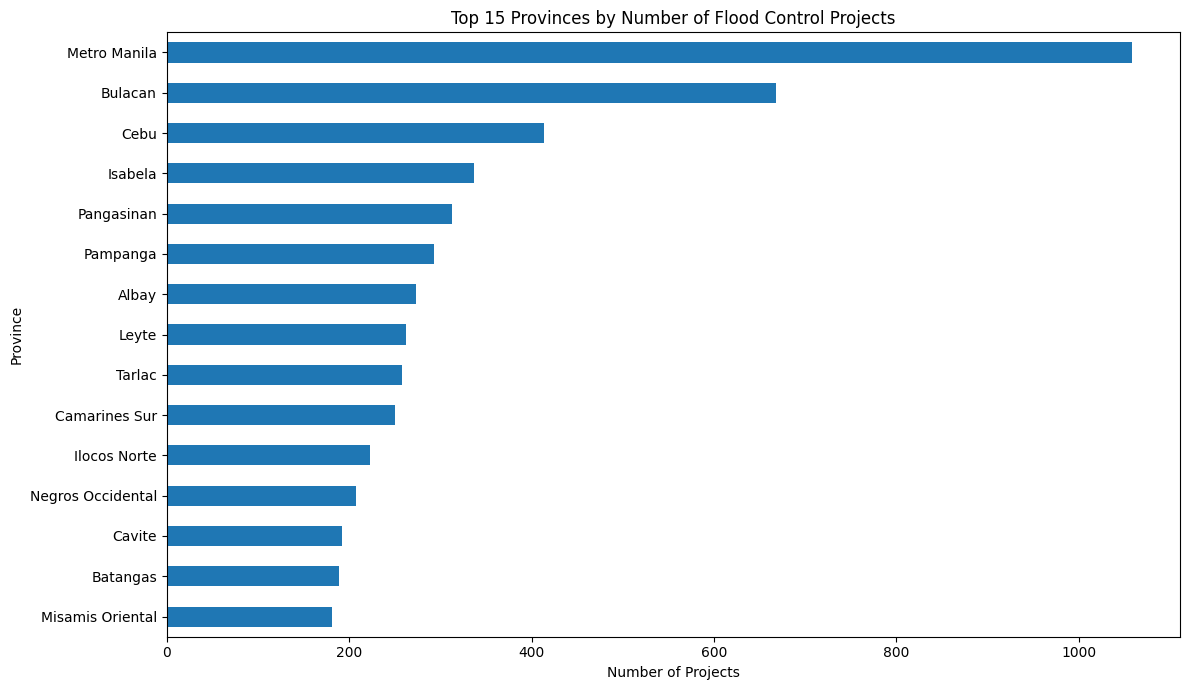

In [ ]:
# Visualize the top 15 provinces by number of projects

plt.figure(figsize=(12, 7))

projects_by_province.sort_values().plot(kind="barh")

plt.title("Top 15 Provinces by Number of Flood Control Projects")
plt.xlabel("Number of Projects")
plt.ylabel("Province")
plt.tight_layout()
plt.show()

### EDA 4: Percentage Share of Top Provinces

In [ ]:
# Calculate the percentage share of the top 15 provinces

province_percentage = (
    df["Province"]
    .value_counts(normalize=True)
    .head(15)
    .mul(100)
    .round(2)
)

display(province_percentage)

,proportion
Province,
Metro Manila,10.74
Bulacan,6.78
Cebu,4.20
Isabela,3.42
Pangasinan,3.18
Pampanga,2.97
Albay,2.77
Leyte,2.66
Tarlac,2.62


##INTERPRETATION

The provincial distribution shows that Metro Manila has the highest number of recorded flood control projects, followed by Bulacan and Cebu. The top 15 provinces have varying levels of project representation, indicating that project records are not evenly distributed across provinces. However, project count alone does not indicate the total amount of funding received, which requires separate financial analysis.

##EDA 5 : TYPE OF WORK

### EDA 5: Distribution of Projects by Type of Work

In [ ]:
# Count projects by type of work
projects_by_type = (
    df["TypeOfWork"]
    .value_counts()
)

# Calculate percentage distribution
type_percentage = (
    df["TypeOfWork"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Combine count and percentage
type_summary = pd.DataFrame({
    "Project Count": projects_by_type,
    "Percentage": type_percentage
})

display(type_summary)

,Project Count,Percentage
TypeOfWork,,
Construction of Flood Mitigation Structure,6352,64.45
Construction of Revetment,747,7.58
Construction of Slope Protection Structure,739,7.50
Construction of Drainage Structure,679,6.89
Rehabilitation / Major Repair of Flood Control Structure,648,6.58
Construction of Dike,225,2.28
Rehabilitation / Major Repair of Drainage Structure,215,2.18
Construction of Flood Mitigation Facility,170,1.73
Rehabilitation / Major Repair of Slope Protection Structure,41,0.42


### EDA 5: Projects by Type of Work Visualization

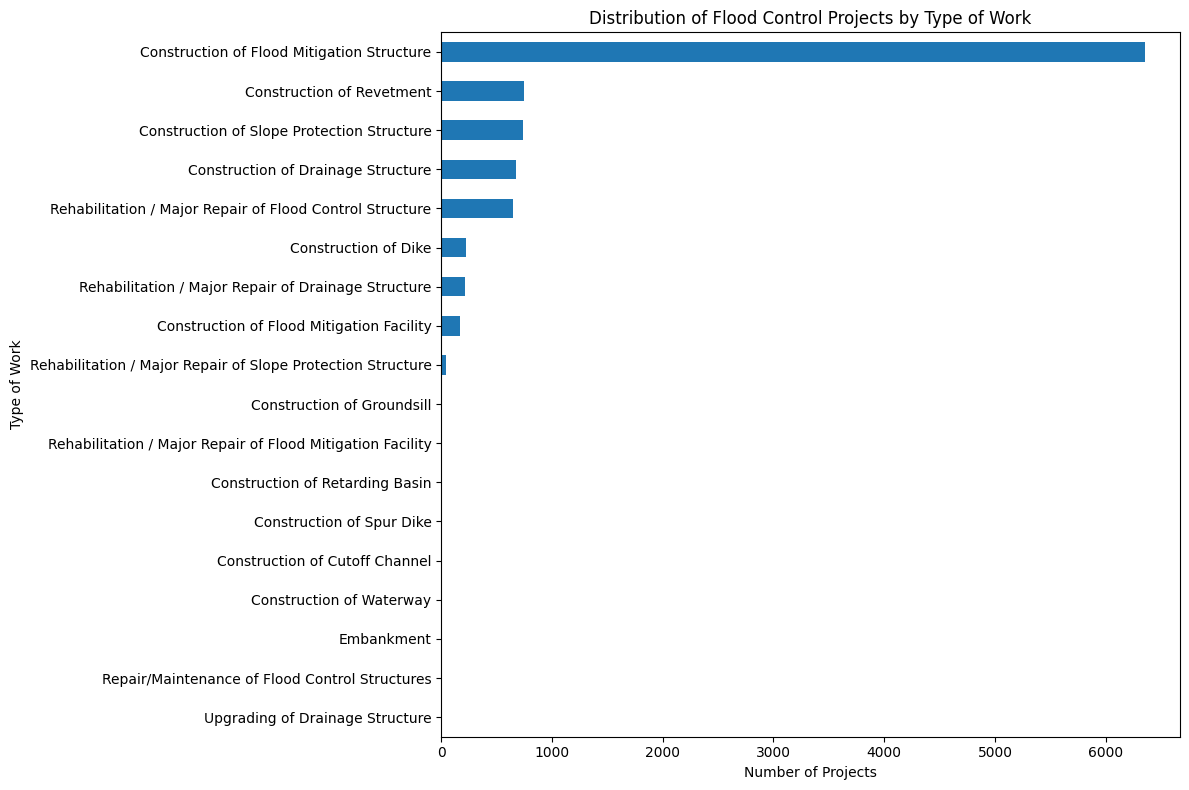

In [ ]:
plt.figure(figsize=(12, 8))

projects_by_type.sort_values().plot(kind="barh")

plt.title("Distribution of Flood Control Projects by Type of Work")
plt.xlabel("Number of Projects")
plt.ylabel("Type of Work")
plt.tight_layout()
plt.show()

### EDA 5: Percentage Distribution by Type of Work

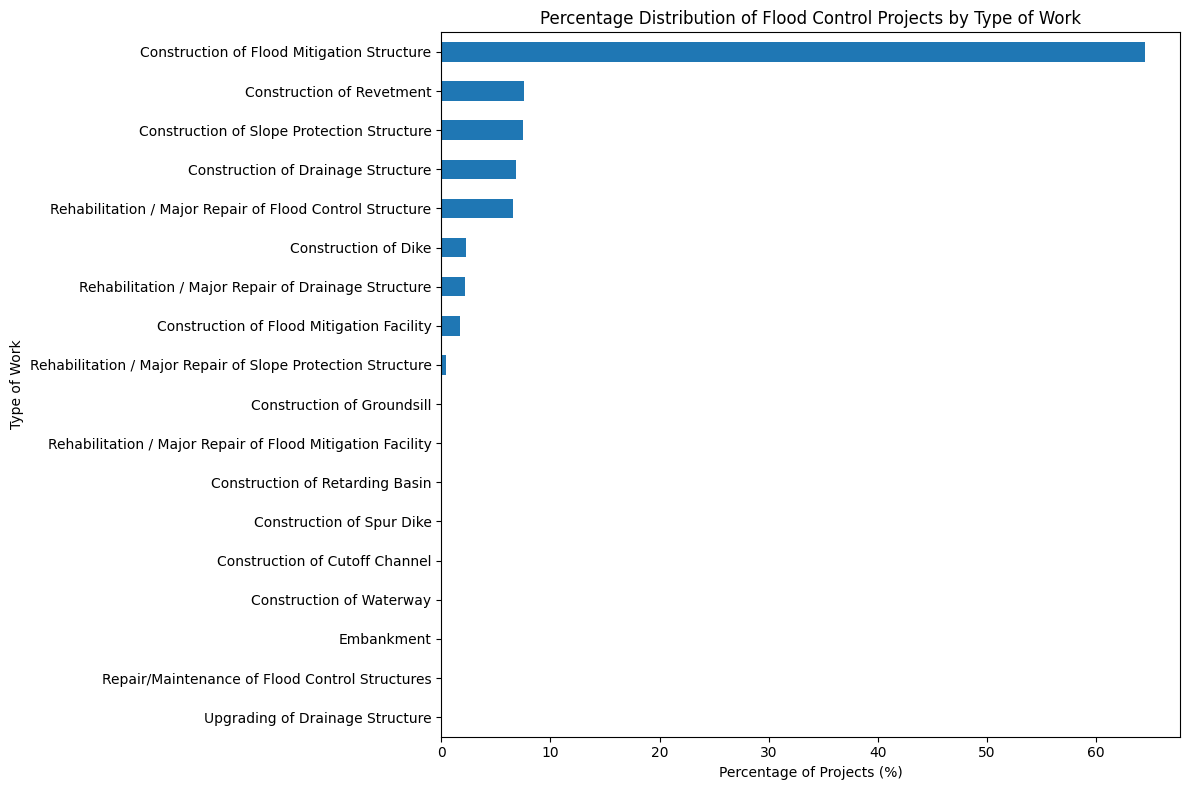

In [ ]:
plt.figure(figsize=(12, 8))

type_percentage.sort_values().plot(kind="barh")

plt.title("Percentage Distribution of Flood Control Projects by Type of Work")
plt.xlabel("Percentage of Projects (%)")
plt.ylabel("Type of Work")
plt.tight_layout()
plt.show()

##INTERPRETATION

Based on the results, the dataset contains 18 different types of flood control work. The most common project type is Construction of Flood Mitigation Structure, with 6,352 projects, making it substantially more prevalent than the other categories. This is followed by Construction of Revetment with 747 projects, Construction of Slope Protection Structure with 739 projects, Construction of Drainage Structure with 679 projects, and Rehabilitation / Major Repair of Flood Control Structure with 648 projects.

The remaining project types have considerably fewer records. Several categories have very limited representation, including Construction of Retarding Basin with 5 projects, Construction of Spur Dike and Rehabilitation / Major Repair of Flood Mitigation Facility with 12 or fewer projects, and three categories with only 1 project each.

Overall, the distribution shows that the dataset is highly concentrated in a small number of flood control project types, particularly flood mitigation structures. This concentration should be considered in later data-mining analyses because categories with very few observations may not provide enough data for reliable pattern analysis.

### EDA 6: Approved Budget vs. Contract Cost

In [ ]:
# Select projects with both financial values available
financial_data = df[
    ["ApprovedBudget_numeric", "ContractCost_numeric"]
].dropna().copy()

# Calculate the difference between approved budget and contract cost
financial_data["BudgetDifference"] = (
    financial_data["ApprovedBudget_numeric"]
    - financial_data["ContractCost_numeric"]
)

# Calculate the percentage difference
financial_data["BudgetDifferencePercent"] = (
    financial_data["BudgetDifference"]
    / financial_data["ApprovedBudget_numeric"]
) * 100

display(financial_data.describe())

,ApprovedBudget_numeric,ContractCost_numeric,BudgetDifference,BudgetDifferencePercent
count,9.698000e+03,9.698000e+03,9.698000e+03,9698.000000
mean,5.671067e+07,5.584604e+07,8.646229e+05,1.471839
std,4.009798e+07,3.950550e+07,6.039573e+06,6.128792
min,1.158000e+06,1.154359e+06,-3.747501e+06,-7.721634
25%,2.744000e+07,2.474980e+07,0.000000e+00,0.000000
50%,4.900000e+07,4.899491e+07,2.329125e+03,0.005019
75%,8.685000e+07,8.656844e+07,2.000023e+05,1.006167
max,3.105763e+08,2.895000e+08,2.364389e+08,97.524001


### EDA 6: Approved Budget vs. Contract Cost

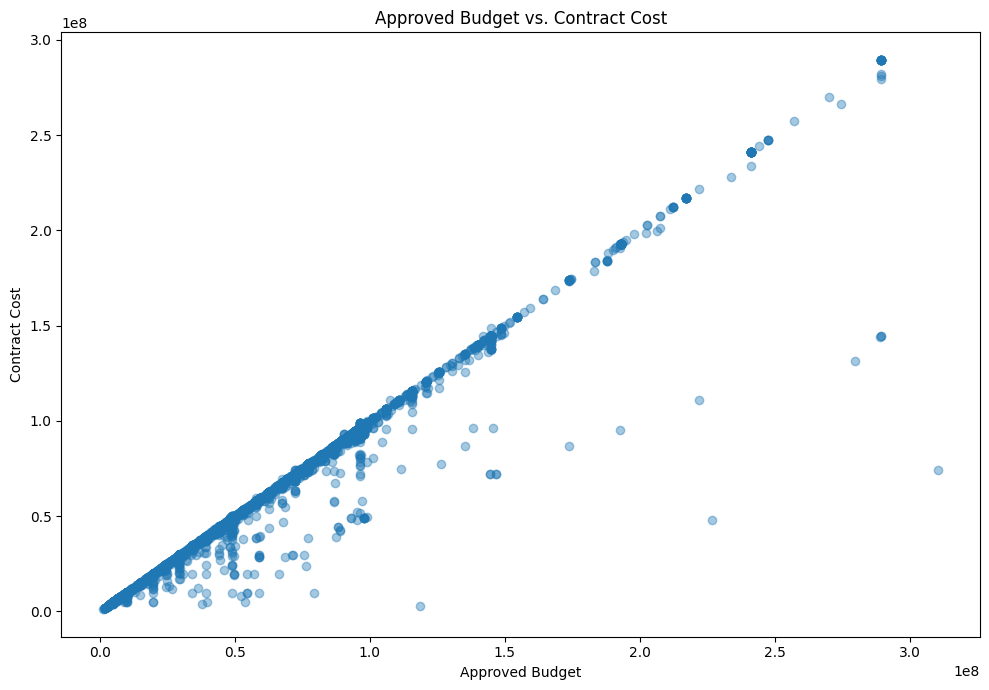

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    financial_data["ApprovedBudget_numeric"],
    financial_data["ContractCost_numeric"],
    alpha=0.4
)

plt.title("Approved Budget vs. Contract Cost")
plt.xlabel("Approved Budget")
plt.ylabel("Contract Cost")
plt.tight_layout()
plt.show()

### EDA 6: Correlation Between Approved Budget and Contract Cost

In [ ]:
financial_correlation = (
    financial_data["ApprovedBudget_numeric"]
    .corr(financial_data["ContractCost_numeric"])
)

print(f"Pearson correlation: {financial_correlation:.4f}")

Pearson correlation: 0.9886


The financial comparison shows that the mean approved budget was approximately ₱56.71 million, while the mean contract cost was approximately ₱55.85 million among the 9,698 projects with both financial values available. This resulted in an average budget difference of approximately ₱864,623, equivalent to an average difference of about 1.47% of the approved budget.

The median budget difference was only approximately ₱2,329, while the median budget difference percentage was approximately 0.005%. This indicates that for at least half of the projects, the approved budget and contract cost were very close in value. However, the standard deviation of the budget difference was approximately ₱6.04 million, showing that some projects had substantially larger differences.

The minimum budget difference was approximately −₱3.75 million, indicating that some contract costs were higher than their corresponding approved budgets. On the other hand, the maximum difference reached approximately ₱236.44 million, with a maximum budget difference percentage of 97.52%, indicating that a small number of projects had substantially lower contract costs compared with their approved budgets.

The Pearson correlation coefficient of 0.9886 indicates a very strong positive linear relationship between approved budget and contract cost. This means that projects with higher approved budgets generally also tend to have higher contract costs. However, correlation does not indicate causation.

Overall, the results suggest that approved budgets and contract costs generally follow a similar pattern, with most projects showing relatively small differences between the two values. However, the presence of projects with large positive or negative differences indicates that some individual projects may warrant further investigation in later data-mining analysis.

##EDA - 7 : PROJECT DURATION

In [ ]:
# EDA 7: Summary Statistics of Project Duration

duration_summary = df["ProjectDurationDays"].describe()

print("Project Duration Summary:")
print(duration_summary)

Project Duration Summary:
count    9855.000000
mean      248.097210
std       137.559406
min        14.000000
25%       161.000000
50%       228.000000
75%       299.000000
max      2012.000000
Name: ProjectDurationDays, dtype: float64


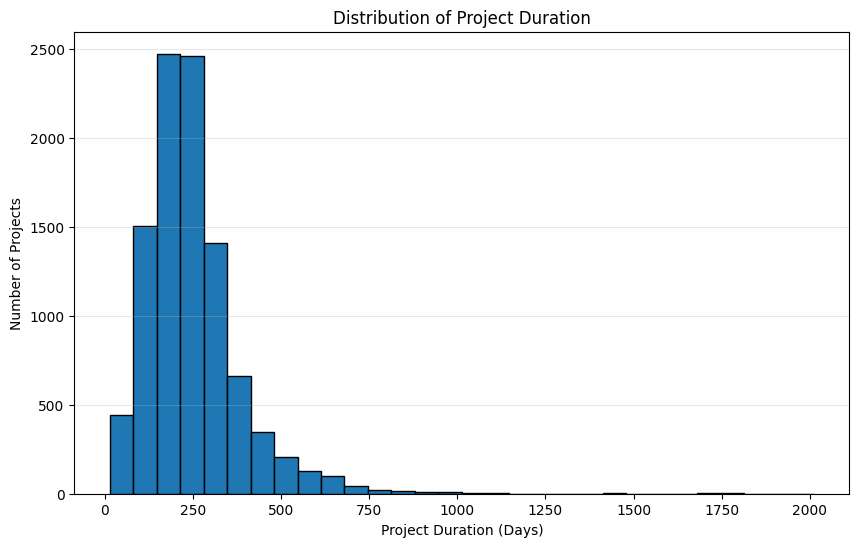

In [ ]:
# EDA 7: Distribution of Project Duration

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df["ProjectDurationDays"], bins=30, edgecolor="black")

plt.title("Distribution of Project Duration")
plt.xlabel("Project Duration (Days)")
plt.ylabel("Number of Projects")
plt.grid(axis="y", alpha=0.3)

plt.show()

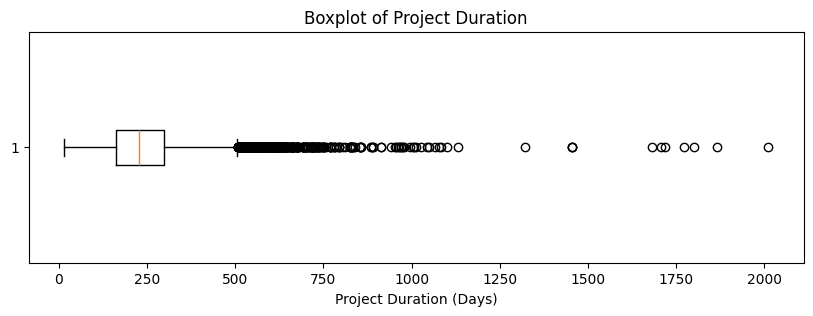

In [ ]:
# EDA 7: Boxplot of Project Duration

plt.figure(figsize=(10, 3))
plt.boxplot(df["ProjectDurationDays"], vert=False)

plt.title("Boxplot of Project Duration")
plt.xlabel("Project Duration (Days)")

plt.show()

##INTERPRETATION

The project duration analysis shows that all 9,855 projects have available duration values. The average project duration is approximately 248 days, while the median is 228 days. The middle 50% of projects have durations between 161 and 299 days, showing that most projects were completed within this range. The shortest recorded project duration is 14 days, while the longest is 2,012 days. The large difference between the maximum duration and the median suggests the presence of projects with unusually long completion periods. These projects may be considered potential outliers and can be examined further during the data-mining stage. Overall, the results indicate considerable variation in the completion time of flood control projects.

In [ ]:
# EDA 8: Top Contractors by Number of Projects

contractor_counts = (
    df["Contractor"]
    .value_counts()
    .head(15)
)

print("Top 15 Contractors by Number of Projects:")
print(contractor_counts)

Top 15 Contractors by Number of Projects:
Contractor
LEGACY CONSTRUCTION CORPORATION (FORMERLY: LEGACY CONSTRUCTION)             115
QM BUILDERS                                                                  88
ALPHA & OMEGA GEN. CONTRACTOR & DEVELOPMENT CORP.                            84
ST. TIMOTHY CONSTRUCTION CORPORATION                                         83
SUNWEST, INC. (FORMERLY: SUNWEST CONSTRUCTION & DEVELOPMENT CORPORATION)     67
CENTERWAYS CONSTRUCTION AND DEVELOPMENT INC.                                 64
TRIPLE 8 CONSTRUCTION & SUPPLY, INC. (FORMERLY TRIPLE 8 CONST. & SUPPLY)     57
ROYAL CROWN MONARCH CONSTRUCTION & SUPPLIES CORP.                            56
WAWAO BUILDERS                                                               53
L.R. TIQUI BUILDERS, INC.                                                    52
HI-TONE CONSTRUCTION & DEVELOPMENT CORP. (FORMERLY                           51
ROAD EDGE TRADING & DEVELOPMENT SERVICES                           

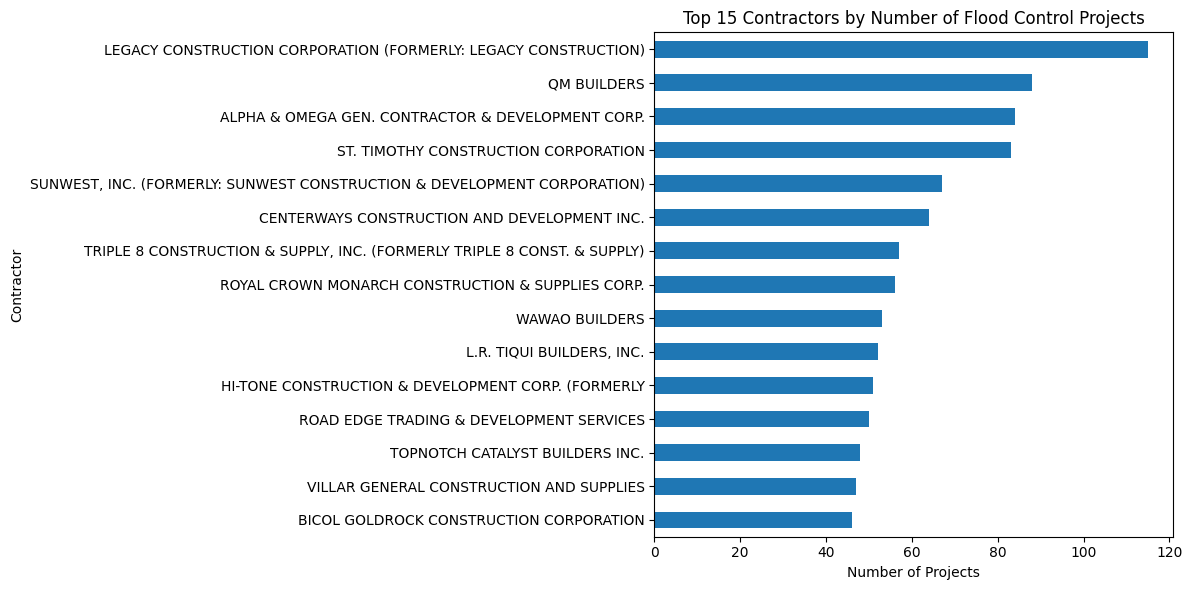

In [ ]:
# EDA 8: Top 15 Contractors Visualization

plt.figure(figsize=(12, 6))

contractor_counts.sort_values().plot(kind="barh")

plt.title("Top 15 Contractors by Number of Flood Control Projects")
plt.xlabel("Number of Projects")
plt.ylabel("Contractor")

plt.tight_layout()
plt.show()

##INTERPRETATION

The contractor analysis shows that LEGACY CONSTRUCTION CORPORATION (FORMERLY: LEGACY CONSTRUCTION) has the highest number of projects among the top contractors, with 115 projects. This is followed by QM BUILDERS with 88 projects and ALPHA & OMEGA GEN. CONTRACTOR & DEVELOPMENT CORP. with 84 projects. Other contractors in the top 15 handled between 46 and 83 projects. Overall, the results show that flood control projects are distributed among many contractors, while a small group of contractors accounts for a relatively higher number of projects. This distribution can be further examined in the succeeding data-mining analysis to identify potential patterns in contractor participation.

In [ ]:
# EDA 9: Contractor Participation Distribution

contractor_project_counts = df["Contractor"].value_counts()

print("Total Number of Unique Contractors:")
print(df["Contractor"].nunique())

print("\nContractor Project Count Summary:")
print(contractor_project_counts.describe())

Total Number of Unique Contractors:
2409

Contractor Project Count Summary:
count    2409.000000
mean        4.090909
std         7.491942
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max       115.000000
Name: count, dtype: float64


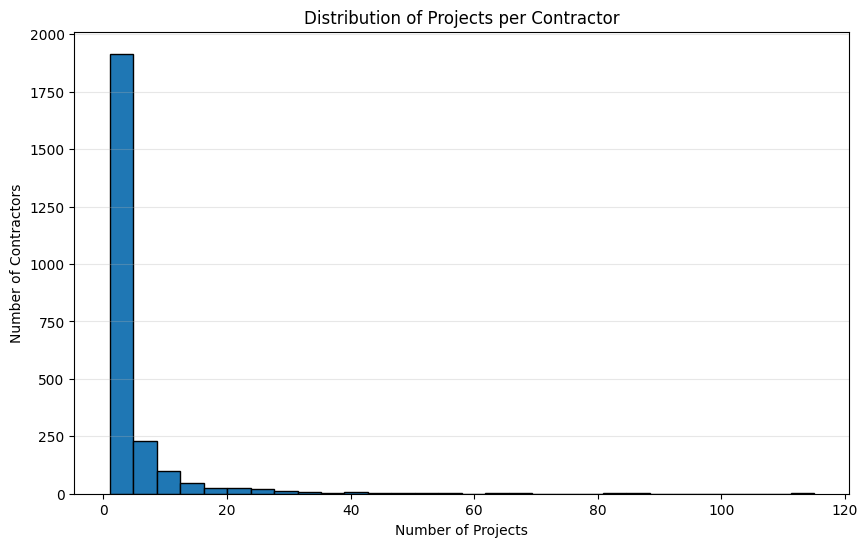

In [ ]:
# EDA 9: Distribution of Projects per Contractor

plt.figure(figsize=(10, 6))

plt.hist(contractor_project_counts, bins=30, edgecolor="black")

plt.title("Distribution of Projects per Contractor")
plt.xlabel("Number of Projects")
plt.ylabel("Number of Contractors")
plt.grid(axis="y", alpha=0.3)

plt.show()

##INTERPRETATION

The dataset contains 2,409 unique contractors involved in the flood control projects. Each contractor handled an average of approximately 4.09 projects, while the median is only 2 projects. The first quartile is 1 project and the third quartile is 4 projects, indicating that most contractors handled relatively few projects. However, the maximum reaches 115 projects, showing that a small number of contractors handled substantially more projects than the majority. The standard deviation of 7.49 projects also indicates considerable variation in contractor participation. Overall, the results suggest that contractor participation is highly uneven, with many contractors handling only a small number of projects while a limited group accounts for a much larger number of projects.

In [ ]:
# EDA 10: Regional and Main Island Project Distribution

region_counts = df["Region"].value_counts()
island_counts = df["MainIsland"].value_counts()

print("Projects by Region:")
print(region_counts)

print("\nProjects by Main Island:")
print(island_counts)

Projects by Region:
Region
Region III                          1617
National Capital Region             1058
Region V                             866
Region I                             851
Region IV-A                          829
Region II                            628
Region VII                           614
Region VIII                          517
Region VI                            505
Region IV-B                          498
Region X                             428
Region XI                            356
Cordillera Administrative Region     352
Region XIII                          302
Region XII                           301
Region IX                            133
Name: count, dtype: int64

Projects by Main Island:
MainIsland
Luzon       6698
Visayas     1637
Mindanao    1520
Name: count, dtype: int64


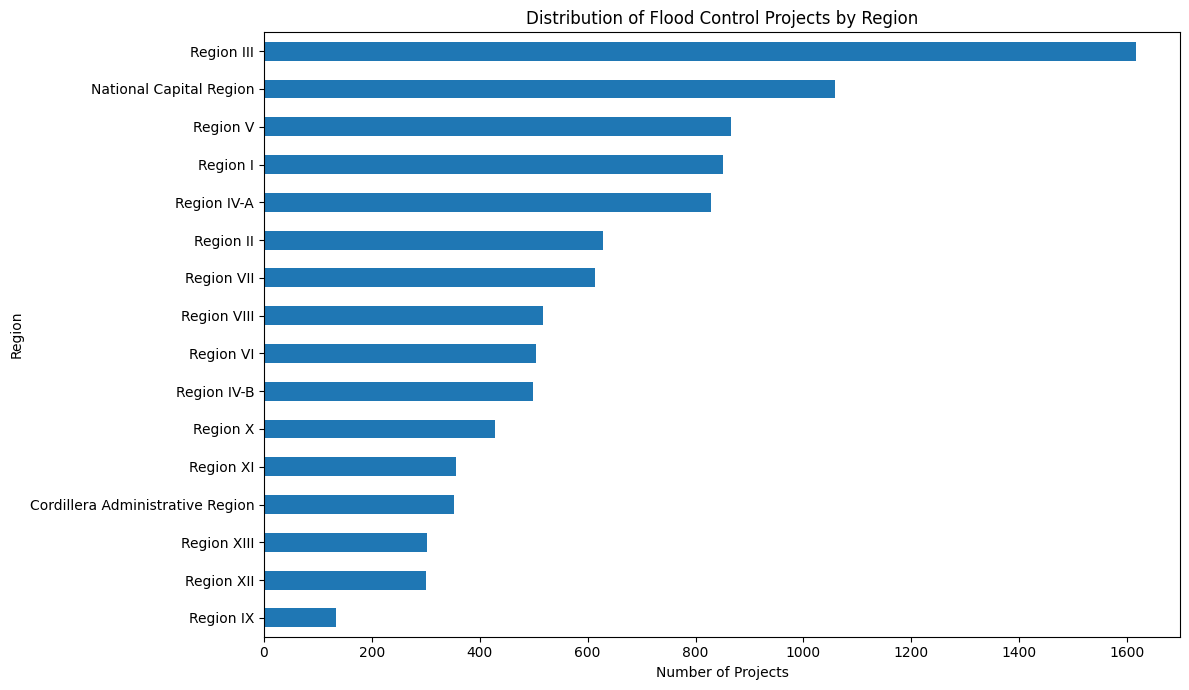

In [ ]:
# EDA 10: Projects by Region Visualization

plt.figure(figsize=(12, 7))

region_counts.sort_values().plot(kind="barh")

plt.title("Distribution of Flood Control Projects by Region")
plt.xlabel("Number of Projects")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

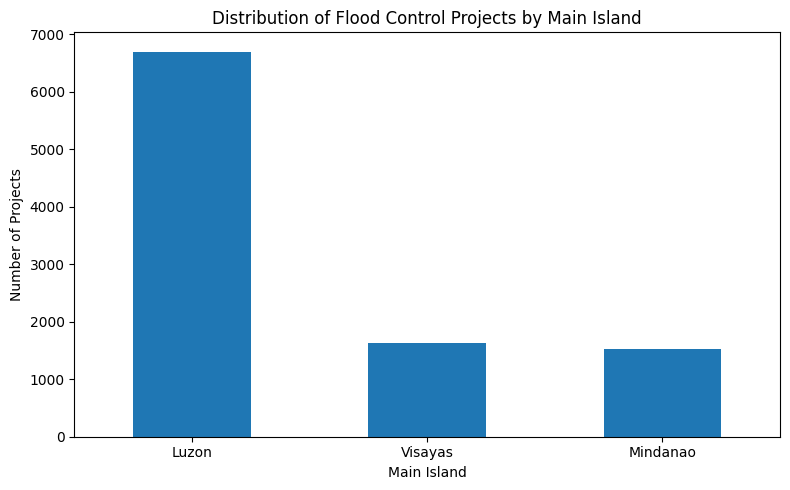

In [ ]:
# EDA 10: Projects by Main Island Visualization

plt.figure(figsize=(8, 5))

island_counts.plot(kind="bar")

plt.title("Distribution of Flood Control Projects by Main Island")
plt.xlabel("Main Island")
plt.ylabel("Number of Projects")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##INTERPRETATION

The regional analysis shows that Region III has the highest number of flood control projects with 1,617 projects, followed by the National Capital Region with 1,058 projects and Region V with 866 projects. In contrast, Region IX has the lowest number of projects with 133 records. The results indicate that project distribution varies considerably across regions.

By main island group, Luzon accounts for the largest share with 6,698 projects, followed by Visayas with 1,637 projects and Mindanao with 1,520 projects. Overall, the dataset is strongly concentrated in Luzon, which contains substantially more project records than the other two main island groups. These results describe the distribution of projects within the dataset and do not necessarily represent the overall distribution of flood control projects or government spending nationwide.

In [ ]:
# EDA 11: Geographic Coordinate Summary

print("Project Latitude Summary:")
print(df["ProjectLatitude"].describe())

print("\nProject Longitude Summary:")
print(df["ProjectLongitude"].describe())

Project Latitude Summary:
count    9855.000000
mean       13.197804
std         3.146945
min         5.767601
25%        10.718490
50%        14.273611
75%        15.157180
max        20.455773
Name: ProjectLatitude, dtype: float64

Project Longitude Summary:
count    9855.000000
mean      122.254094
std         1.768041
min       117.061736
25%       120.910978
50%       121.435556
75%       123.722497
max       126.569467
Name: ProjectLongitude, dtype: float64


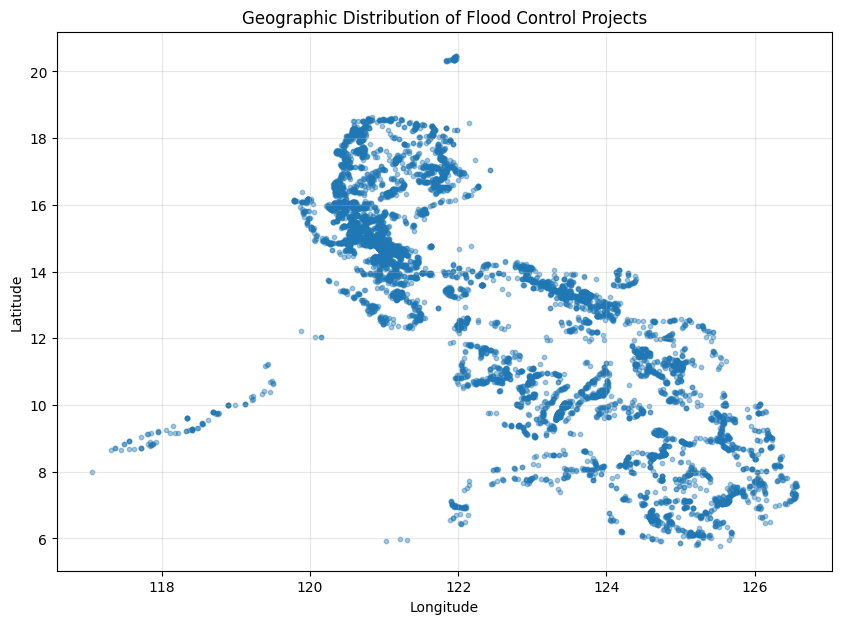

In [ ]:
# EDA 11: Geographic Distribution of Project Locations

plt.figure(figsize=(10, 7))

plt.scatter(
    df["ProjectLongitude"],
    df["ProjectLatitude"],
    alpha=0.4,
    s=10
)

plt.title("Geographic Distribution of Flood Control Projects")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.3)

plt.show()

##INTERPRETATION

The geographic analysis shows that all 9,855 projects have available latitude and longitude coordinates. Project latitudes range from 5.77° to 20.46°, while longitudes range from 117.06° to 126.57°. The mean project location is approximately 13.20° latitude and 122.25° longitude. The geographic range indicates that the recorded flood control projects are distributed across a wide area of the Philippines. The scatter plot can further show the spatial concentration and distribution of the project locations. Overall, the geographic data provides a useful basis for identifying spatial patterns in the subsequent data-mining analysis.

In [ ]:
# EDA 12: Relationship Between Approved Budget and Contract Cost

financial_data = df[
    ["ApprovedBudget_numeric", "ContractCost_numeric"]
].dropna()

correlation = financial_data[
    "ApprovedBudget_numeric"
].corr(
    financial_data["ContractCost_numeric"]
)

print("Pearson Correlation between Approved Budget and Contract Cost:")
print(round(correlation, 4))

Pearson Correlation between Approved Budget and Contract Cost:
0.9886


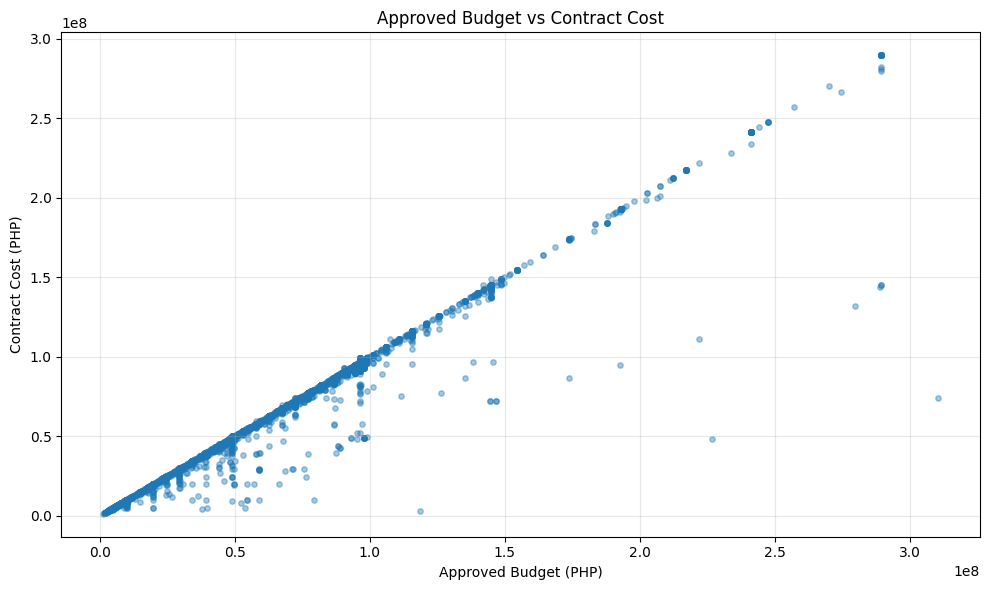

In [ ]:
# EDA 12: Approved Budget vs Contract Cost

plt.figure(figsize=(10, 6))

plt.scatter(
    financial_data["ApprovedBudget_numeric"],
    financial_data["ContractCost_numeric"],
    alpha=0.4,
    s=15
)

plt.title("Approved Budget vs Contract Cost")
plt.xlabel("Approved Budget (PHP)")
plt.ylabel("Contract Cost (PHP)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

##Data Mining 1: Data Preparation for K-Means Clustering

In [ ]:
# Data Mining 1: Select Variables for K-Means Clustering

clustering_data = df[
    [
        "ApprovedBudget_numeric",
        "ContractCost_numeric",
        "ProjectDurationDays",
        "ContractorCount",
        "ProjectLatitude",
        "ProjectLongitude"
    ]
].copy()

print("Clustering Variables:")
print(clustering_data.head())

print("\nMissing Values:")
print(clustering_data.isnull().sum())

Clustering Variables:
   ApprovedBudget_numeric  ContractCost_numeric  ProjectDurationDays  \
0              96500000.0           92692943.80                  564   
1              49000000.0           47521251.30                  358   
2              47423180.0           45942583.67                  362   
3               9900000.0            9900000.00                  379   
4               4950000.0            4950000.00                  296   

   ContractorCount  ProjectLatitude  ProjectLongitude  
0                1         18.25091        121.047570  
1                1         18.51180        121.078290  
2                1         18.27023        121.420220  
3                1         18.53566        121.080200  
4                1         18.52723        121.096812  

Missing Values:
ApprovedBudget_numeric    157
ContractCost_numeric       28
ProjectDurationDays         0
ContractorCount             0
ProjectLatitude             0
ProjectLongitude            0
dtype: int64

In [ ]:
# Data Mining 1: Remove Missing Values for Clustering

clustering_data = clustering_data.dropna()

print("Number of Records Before Removing Missing Values:", len(df))
print("Number of Records Available for Clustering:", len(clustering_data))

print("\nMissing Values After Cleaning:")
print(clustering_data.isnull().sum())

Number of Records Before Removing Missing Values: 9855
Number of Records Available for Clustering: 9698

Missing Values After Cleaning:
ApprovedBudget_numeric    0
ContractCost_numeric      0
ProjectDurationDays       0
ContractorCount           0
ProjectLatitude           0
ProjectLongitude          0
dtype: int64


In [ ]:
# Data Mining 1: Standardize Clustering Variables

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

clustering_scaled = scaler.fit_transform(clustering_data)

print("Standardized Data Shape:")
print(clustering_scaled.shape)

Standardized Data Shape:
(9698, 6)


In [ ]:
# Data Mining 1: Create Standardized DataFrame

clustering_scaled_df = pd.DataFrame(
    clustering_scaled,
    columns=clustering_data.columns,
    index=clustering_data.index
)

print("Standardized Clustering Data:")
print(clustering_scaled_df.head())

print("\nSummary Statistics:")
print(clustering_scaled_df.describe())

Standardized Clustering Data:
   ApprovedBudget_numeric  ContractCost_numeric  ProjectDurationDays  \
0                0.992354              0.932751             2.351929   
1               -0.192306             -0.210736             0.824484   
2               -0.231632             -0.250699             0.854143   
3               -1.167467             -1.163089             0.980194   
4               -1.290921             -1.288394             0.364767   

   ContractorCount  ProjectLatitude  ProjectLongitude  
0        -0.395195         1.599135         -0.673127  
1        -0.395195         1.681896         -0.655741  
2        -0.395195         1.605264         -0.462217  
3        -0.395195         1.689465         -0.654660  
4        -0.395195         1.686790         -0.645258  

Summary Statistics:
       ApprovedBudget_numeric  ContractCost_numeric  ProjectDurationDays  \
count            9.698000e+03          9.698000e+03         9.698000e+03   
mean             1.289498e-1

##Data Mining 2: Elbow Method for K-Means

In [ ]:
# Data Mining 2: Elbow Method for K-Means

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(clustering_scaled)
    inertia_values.append(kmeans.inertia_)

print("Inertia Values:")
for k, inertia in zip(k_values, inertia_values):
    print(f"K={k}: {inertia:.2f}")

Inertia Values:
K=2: 43805.09
K=3: 34247.31
K=4: 27449.20
K=5: 23879.65
K=6: 21268.17
K=7: 19096.15
K=8: 17091.35
K=9: 15815.71
K=10: 14909.59


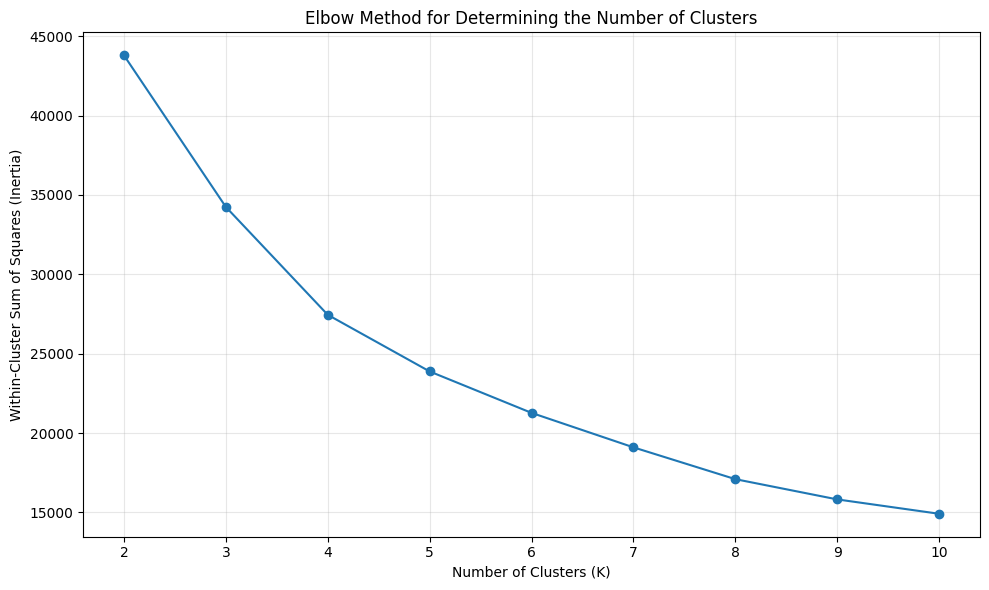

In [ ]:
# Data Mining 2: Elbow Method Visualization

plt.figure(figsize=(10, 6))

plt.plot(
    k_values,
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Determining the Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

##Data Mining 3: K-Means Clustering

In [ ]:
# Data Mining 3: Apply K-Means Clustering

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(clustering_scaled)

clustering_data["Cluster"] = cluster_labels

print("Number of Projects in Each Cluster:")
print(clustering_data["Cluster"].value_counts().sort_index())

Number of Projects in Each Cluster:
Cluster
0    3487
1    1831
2    1228
3    1044
4    2108
Name: count, dtype: int64


##Data Mining 4: Cluster Profile

In [ ]:
# Data Mining 4: Cluster Profile

cluster_profile = (
    clustering_data
    .groupby("Cluster")
    [
        [
            "ApprovedBudget_numeric",
            "ContractCost_numeric",
            "ProjectDurationDays",
            "ContractorCount",
            "ProjectLatitude",
            "ProjectLongitude"
        ]
    ]
    .mean()
    .round(2)
)

print("Cluster Profile:")
print(cluster_profile)

Cluster Profile:
         ApprovedBudget_numeric  ContractCost_numeric  ProjectDurationDays  \
Cluster                                                                      
0                   30081530.19           29677341.28               207.97   
1                   99316988.86           98291966.02               254.89   
2                   75665453.03           74763233.27               260.38   
3                   95425104.53           93348680.75               410.62   
4                   33536699.30           32671814.63               214.98   

         ContractorCount  ProjectLatitude  ProjectLongitude  
Cluster                                                      
0                   1.00            15.33            120.98  
1                   1.01            14.94            121.24  
2                   2.00            13.28            122.21  
3                   1.07             9.18            124.50  
4                   1.00            10.15            124.08  


##Data Mining 5: Cluster Visualization

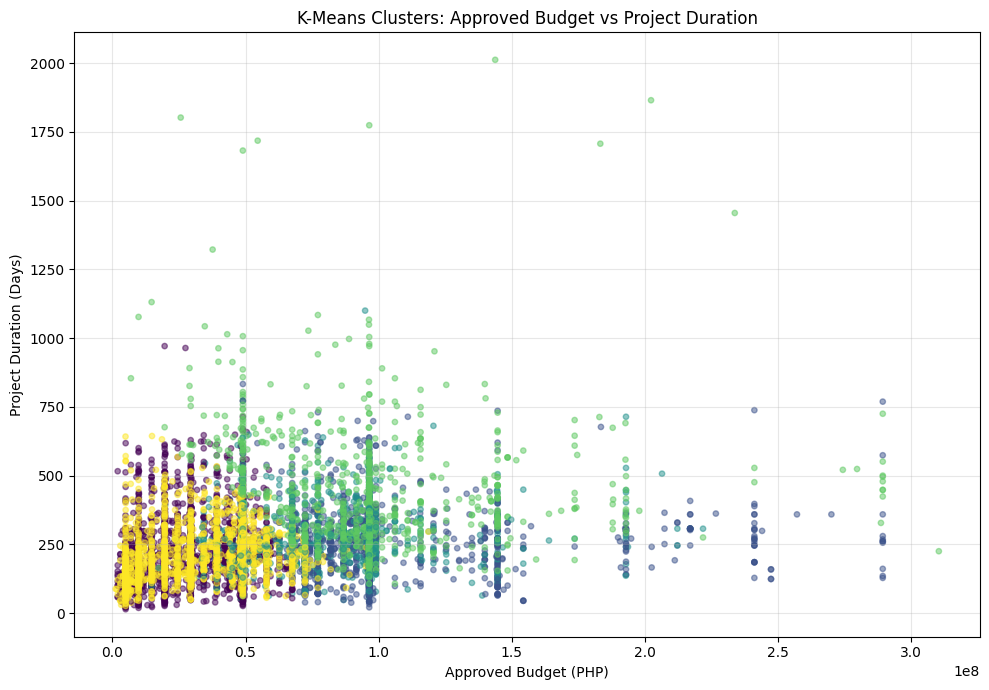

In [ ]:
# Data Mining 5: Visualize K-Means Clusters

plt.figure(figsize=(10, 7))

plt.scatter(
    clustering_data["ApprovedBudget_numeric"],
    clustering_data["ProjectDurationDays"],
    c=clustering_data["Cluster"],
    alpha=0.5,
    s=15
)

plt.title("K-Means Clusters: Approved Budget vs Project Duration")
plt.xlabel("Approved Budget (PHP)")
plt.ylabel("Project Duration (Days)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

##Data Mining 6: K-Means Cluster Validation

In [ ]:
# Data Mining 6: Silhouette Score for K-Means

from sklearn.metrics import silhouette_score

silhouette = silhouette_score(
    clustering_scaled,
    cluster_labels
)

print("Silhouette Score for K=5:")
print(round(silhouette, 4))

Silhouette Score for K=5:
0.3305


##Data Mining 7: Compare Silhouette Scores

In [ ]:
# Data Mining 7: Compare Silhouette Scores for Different K Values

silhouette_values = []

for k in range(2, 11):
    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    test_labels = kmeans_test.fit_predict(clustering_scaled)

    score = silhouette_score(
        clustering_scaled,
        test_labels
    )

    silhouette_values.append(score)

print("Silhouette Scores:")

for k, score in zip(range(2, 11), silhouette_values):
    print(f"K={k}: {score:.4f}")

Silhouette Scores:
K=2: 0.2922
K=3: 0.2924
K=4: 0.3330
K=5: 0.3305
K=6: 0.3204
K=7: 0.3361
K=8: 0.3527
K=9: 0.2940
K=10: 0.2830


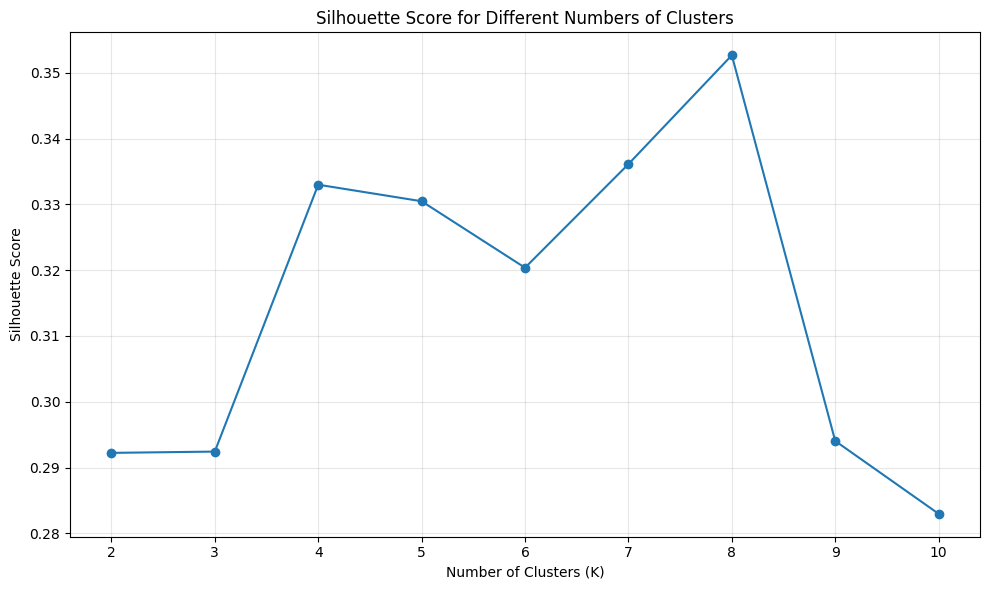

In [ ]:
# Data Mining 7: Silhouette Score Visualization

plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score for Different Numbers of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

##Data Mining 8: Final K-Means Model

In [ ]:
# Data Mining 8: Final K-Means Clustering with K=8

final_kmeans = KMeans(
    n_clusters=8,
    random_state=42,
    n_init=10
)

final_cluster_labels = final_kmeans.fit_predict(clustering_scaled)

clustering_data["Cluster"] = final_cluster_labels

print("Number of Projects in Each Final Cluster:")
print(
    clustering_data["Cluster"]
    .value_counts()
    .sort_index()
)

Number of Projects in Each Final Cluster:
Cluster
0     508
1     456
2    3276
3    1680
4    1983
5     751
6     896
7     148
Name: count, dtype: int64


In [ ]:
# Data Mining 8: Final Cluster Profile

final_cluster_profile = (
    clustering_data
    .groupby("Cluster")
    [
        [
            "ApprovedBudget_numeric",
            "ContractCost_numeric",
            "ProjectDurationDays",
            "ContractorCount",
            "ProjectLatitude",
            "ProjectLongitude"
        ]
    ]
    .mean()
    .round(2)
)

print("Final K-Means Cluster Profile:")
print(final_cluster_profile)

Final K-Means Cluster Profile:
         ApprovedBudget_numeric  ContractCost_numeric  ProjectDurationDays  \
Cluster                                                                      
0                  7.822329e+07          7.677865e+07               298.23   
1                  5.300747e+07          5.161896e+07               599.09   
2                  2.931219e+07          2.895409e+07               191.55   
3                  9.168209e+07          9.057380e+07               240.45   
4                  3.220489e+07          3.141281e+07               209.72   
5                  7.285409e+07          7.215077e+07               247.82   
6                  9.462129e+07          9.365546e+07               316.56   
7                  2.206903e+08          2.138069e+08               349.74   

         ContractorCount  ProjectLatitude  ProjectLongitude  
Cluster                                                      
0                   2.00             9.78            124.34  
1 

##Data Mining 9: Final K-Means Cluster Visualization

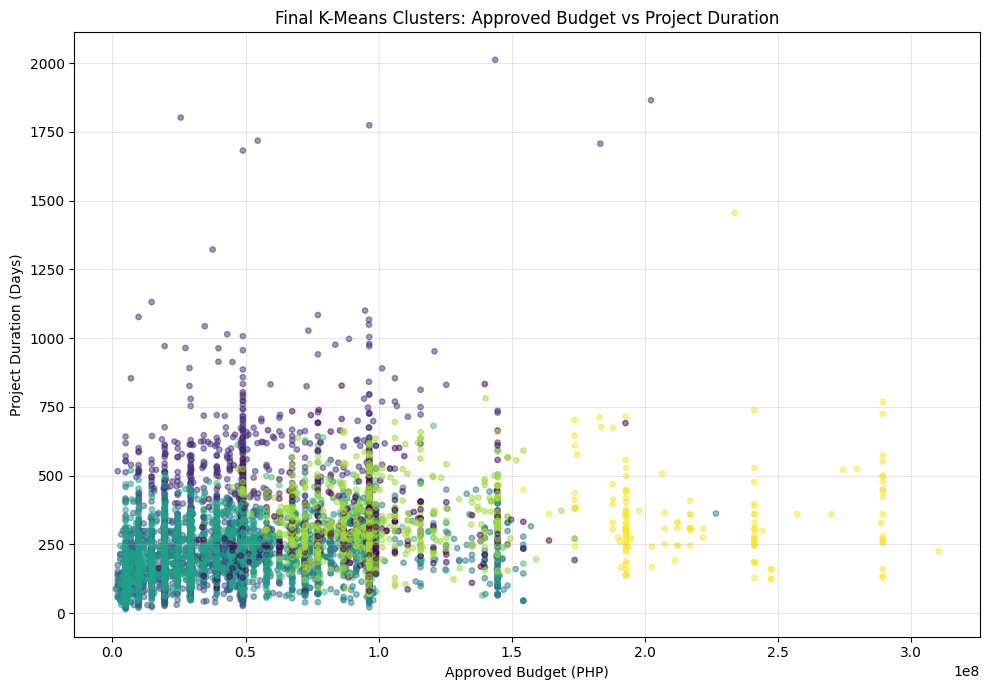

In [ ]:
# Data Mining 9: Final K-Means Cluster Visualization

plt.figure(figsize=(10, 7))

plt.scatter(
    clustering_data["ApprovedBudget_numeric"],
    clustering_data["ProjectDurationDays"],
    c=clustering_data["Cluster"],
    alpha=0.5,
    s=15
)

plt.title("Final K-Means Clusters: Approved Budget vs Project Duration")
plt.xlabel("Approved Budget (PHP)")
plt.ylabel("Project Duration (Days)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

##Data Mining 10: Outlier Detection Using Isolation Forest

In [ ]:
# Data Mining 10: Prepare Data for Outlier Detection

from sklearn.ensemble import IsolationForest

outlier_data = df[
    [
        "ApprovedBudget_numeric",
        "ContractCost_numeric",
        "ProjectDurationDays"
    ]
].dropna()

print("Records Available for Outlier Detection:")
print(len(outlier_data))

print("\nVariables Used:")
print(outlier_data.columns.tolist())

Records Available for Outlier Detection:
9698

Variables Used:
['ApprovedBudget_numeric', 'ContractCost_numeric', 'ProjectDurationDays']


In [ ]:
# Data Mining 10: Isolation Forest

isolation_forest = IsolationForest(
    contamination=0.05,
    random_state=42
)

outlier_labels = isolation_forest.fit_predict(outlier_data)

outlier_data["Outlier"] = outlier_labels

print("Outlier Classification:")
print(
    outlier_data["Outlier"]
    .value_counts()
    .sort_index()
)

Outlier Classification:
Outlier
-1     485
 1    9213
Name: count, dtype: int64


In [ ]:
# Data Mining 10: Outlier Summary

normal_projects = (outlier_data["Outlier"] == 1).sum()
potential_outliers = (outlier_data["Outlier"] == -1).sum()

print("Normal Projects:", normal_projects)
print("Potential Outliers:", potential_outliers)

print(
    "\nPercentage of Potential Outliers:",
    round(
        potential_outliers / len(outlier_data) * 100,
        2
    ),
    "%"
)

Normal Projects: 9213
Potential Outliers: 485

Percentage of Potential Outliers: 5.0 %


##Data Mining 11: Outlier Profile

In [ ]:
# Data Mining 11: Compare Normal Projects and Potential Outliers

outlier_profile = (
    outlier_data
    .groupby("Outlier")
    [
        [
            "ApprovedBudget_numeric",
            "ContractCost_numeric",
            "ProjectDurationDays"
        ]
    ]
    .mean()
    .round(2)
)

outlier_profile.index = [
    "Potential Outliers" if value == -1 else "Normal Projects"
    for value in outlier_profile.index
]

print("Outlier Profile:")
print(outlier_profile)

Outlier Profile:
                    ApprovedBudget_numeric  ContractCost_numeric  \
Potential Outliers            1.420707e+08          1.385419e+08   
Normal Projects               5.221706e+07          5.149268e+07   

                    ProjectDurationDays  
Potential Outliers               465.52  
Normal Projects                  235.29  


In [ ]:
# Data Mining 11: Potential Outlier Records

potential_outliers = outlier_data[
    outlier_data["Outlier"] == -1
].copy()

potential_outliers = potential_outliers.sort_values(
    "ProjectDurationDays",
    ascending=False
)

print("Top 20 Potential Outliers by Project Duration:")
print(potential_outliers.head(20))

Top 20 Potential Outliers by Project Duration:
      ApprovedBudget_numeric  ContractCost_numeric  ProjectDurationDays  \
2889            1.438413e+08          1.363022e+08                 2012   
5833            2.024096e+08          1.983605e+08                 1865   
5338            2.564660e+07          2.464616e+07                 1802   
5335            9.650000e+07          9.273898e+07                 1774   
5336            5.457075e+07          5.244267e+07                 1718   
6832            1.833500e+08          1.831822e+08                 1707   
5337            4.900000e+07          4.708881e+07                 1682   
7953            2.338760e+08          2.278123e+08                 1455   
5845            3.764180e+07          3.650023e+07                 1322   
352             1.470000e+07          1.310684e+07                 1131   
361             9.495390e+07          9.490780e+07                 1100   
8729            7.720000e+07          7.720000e+07   

##Data Mining 12: Identify Potential Outlier Projects

In [ ]:
# Data Mining 12: Identify Potential Outlier Projects

outlier_indices = potential_outliers.index

outlier_projects = df.loc[
    outlier_indices,
    [
        "ProjectId",
        "ProjectName",
        "Region",
        "Province",
        "Municipality",
        "TypeOfWork",
        "Contractor",
        "ApprovedBudget_numeric",
        "ContractCost_numeric",
        "ProjectDurationDays"
    ]
].copy()

outlier_projects = outlier_projects.sort_values(
    "ProjectDurationDays",
    ascending=False
)

print("Top 20 Potential Outlier Projects:")
print(outlier_projects.head(20).to_string(index=False))

Top 20 Potential Outlier Projects:
  ProjectId                                                                                                                                                 ProjectName                  Region            Province          Municipality                                          TypeOfWork                                                                                                           Contractor  ApprovedBudget_numeric  ContractCost_numeric  ProjectDurationDays
P00222127LZ                                                                                                Almacen River Improvement Project, Hermosa and Orani, Bataan              Region III              Bataan                   NaN          Construction of Flood Mitigation Structure                                                                    TOKWING CONSTRUCTION, CORP.(FOR; TOKWING CONSTRUC            143841299.98          136302210.19                 2012
P00223199MN              

##Data Mining 12: Outlier Analysis Interpretation

The Isolation Forest identified 485 potential outliers out of 9,698 analyzed projects, representing 5% of the dataset. Compared with the 9,213 normal projects, the potential outliers have substantially higher average approved budgets and contract costs and considerably longer project durations.

The average approved budget of the potential outliers was approximately ₱142.07 million, compared with ₱52.22 million for normal projects. Their average contract cost was approximately ₱138.54 million, compared with ₱51.49 million for normal projects. Their average duration was also substantially longer at 465.52 days, compared with 235.29 days for normal projects.

The individual outlier records show several projects with exceptionally long durations. The longest identified project had a duration of 2,012 days, followed by projects lasting 1,865, 1,802, 1,774, and 1,718 days. Several of these projects involve flood mitigation structures, while others involve drainage systems, embankments, and revetments. The outliers are distributed across several regions and provinces rather than being concentrated in a single location.

These results indicate that the potential outliers are generally associated with larger financial values, longer project durations, or unusual combinations of these characteristics. However, being classified as an outlier does not necessarily mean that a project is problematic or inefficient. The projects may have legitimate differences in scope, complexity, location, or implementation requirements.

##Overall Data Mining Findings

Now that the EDA and Data Mining stages are complete. This section summarizes the most important patterns discovered from the dataset without introducing new analysis.

1. Project Distribution

The dataset contains 9,855 flood control infrastructure projects distributed across the Philippines. The projects are concentrated in Luzon, which accounts for 6,698 records or 67.97% of the dataset. Region III has the highest number of projects with 1,617 records.

2. Project Type

The dataset contains 18 types of flood control work. Construction of Flood Mitigation Structure is the dominant category with 6,352 projects or 64.45% of all records. This shows that the dataset is strongly concentrated in a small number of project types.

3. Financial Characteristics

The financial analysis showed a very strong positive relationship between approved budget and contract cost with a Pearson correlation of 0.9886. Most projects have relatively close approved budget and contract cost values. However, some projects have substantially larger differences that may warrant further examination.

4. Project Duration

The average project duration is approximately 248 days, while the median is 228 days. The longest recorded duration is 2,012 days, indicating considerable variation in project completion periods.

5. K-Means Clustering

The Silhouette Method showed that K = 8 produced the highest silhouette score among the tested values, with a score of 0.3527. The resulting eight clusters revealed different project profiles based on financial values, duration, contractor count, and geographic location.

Some clusters represent relatively lower-cost and shorter-duration projects, while others contain higher-cost or longer-duration projects. One cluster had an average duration of approximately 599 days, while another had an average approved budget of approximately ₱220.69 million.

6. Outlier Detection

The Isolation Forest identified 485 potential outliers out of 9,698 analyzed projects, equivalent to 5% of the records used for this analysis. These potential outliers had an average approved budget of approximately ₱142.07 million and an average project duration of 465.52 days, substantially higher than the normal projects.

Several potential outliers had durations exceeding 1,000 days, with the longest reaching 2,012 days. These records should be interpreted as statistically unusual projects rather than automatically being considered problematic.

**Overall Finding**

The data-mining analysis shows that Philippine flood control infrastructure projects exhibit substantial variation in geographic distribution, project type, financial characteristics, implementation duration, and contractor participation. K-Means clustering identified eight distinct project groups, while Isolation Forest highlighted a smaller group of statistically unusual projects. Together, these findings demonstrate that data mining can be used to identify project patterns and unusual characteristics within flood control infrastructure data.

## Recommendations

The following recommendations are based on the results of the exploratory analysis, clustering, and outlier detection.

1. **Prioritize monitoring of projects with unusually long durations.**  
   Projects with substantially longer completion periods should be reviewed to determine whether the extended duration is related to project scope, location, implementation conditions, or other factors.

2. **Review projects with large differences between approved budgets and contract costs.**  
   Although the analysis showed a very strong relationship between approved budgets and contract costs, projects with unusually large budget differences may require additional examination to understand the reasons for the variation.

3. **Use project clusters to support project classification and monitoring.**  
   The K-Means results identified groups with different combinations of budget, duration, contractor participation, and geographic characteristics. These clusters can be used as a basis for comparing projects with similar profiles.

4. **Further investigate potential outliers rather than automatically removing them.**  
   The 485 potential outliers identified by Isolation Forest should be validated using project records and implementation information. An outlier may represent a legitimate large-scale or complex project and should not automatically be considered problematic.

5. **Improve data completeness and consistency.**  
   Missing municipality information and non-numeric financial entries should be reviewed and standardized where possible. Consistent data recording would improve the reliability of future analysis and data-mining models.

6. **Expand future analysis using additional project-related variables.**  
   Future studies may incorporate information such as project status, flood hazard levels, rainfall data, river characteristics, population exposure, project location, and actual flood occurrence. These additional variables could provide stronger insights into the relationship between infrastructure projects and flood-related conditions.

7. **Develop a monitoring dashboard for decision support.**  
   The identified patterns can be presented through an interactive dashboard showing project locations, project types, budgets, durations, contractor participation, clusters, and potential outliers. This can make the analysis easier to interpret and use for project monitoring.

## Final Summary

This study analyzed 9,855 DPWH flood control infrastructure projects in the Philippines using exploratory data analysis and data-mining techniques. The exploratory analysis showed that the projects were concentrated in Luzon and in several major regions and project types. Construction of Flood Mitigation Structure was the most common type of work, accounting for 64.45% of the recorded projects.

The financial analysis showed a very strong positive relationship between approved budgets and contract costs, with a Pearson correlation coefficient of 0.9886. The project duration analysis showed an average duration of approximately 248 days and a median of 228 days. Several projects had substantially longer durations and were further examined through outlier detection.

K-Means clustering was applied using financial, duration, contractor, and geographic variables. After testing different values of K, eight clusters were selected based on the highest silhouette score of 0.3527. The resulting clusters showed differences in project budgets, durations, contractor participation, and geographic characteristics.

Isolation Forest was also used to identify potential unusual projects. Among the 9,698 projects with complete financial data, 485 projects were classified as potential outliers. These projects generally had higher average budgets and longer project durations than the normal projects.

Overall, the study demonstrates how exploratory analysis and data-mining techniques can be used to identify patterns, group similar flood control projects, and detect potentially unusual records. The results can serve as a basis for further investigation, project monitoring, and future development of data-driven decision-support tools for flood control infrastructure management.